# 07 — AML Drug-Repurposing Screening

This notebook applies the selected GAT + CNN drug–target affinity model to AML-related protein targets and candidate drugs.

The screening workflow consists of:

1. Preparing and validating AML target proteins
2. Preparing and validating candidate drug molecules
3. Identifying whether drugs and targets were represented in KIBA
4. Generating all candidate drug–target combinations
5. Predicting affinity scores
6. Ranking potential AML repurposing candidates

Predictions for targets or drugs absent from KIBA will be clearly labelled as unseen or out-of-training-distribution predictions.

# Imports and project setup

In [1]:
from pathlib import Path
import json
import re
import sys

import numpy as np
import pandas as pd

from rdkit import Chem

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import config as cfg

from src.utils import (
    set_random_seed,
)

set_random_seed(cfg.RANDOM_SEED)

AML_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "aml"
)

AML_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PROCESSED_DATA_DIR = cfg.PROCESSED_DATA_DIR
METRICS_DIR = cfg.METRICS_DIR

MAX_PROTEIN_LENGTH = (
    cfg.MAX_PROTEIN_LENGTH
)

print("Project root:", PROJECT_ROOT)
print("AML data directory:", AML_DATA_DIR)
print(
    "Maximum protein length:",
    MAX_PROTEIN_LENGTH,
)

Project root: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing
AML data directory: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml
Maximum protein length: 1000


# Define AML input and output paths

In [2]:
aml_targets_source_path = (
    AML_DATA_DIR
    / "aml_targets.csv"
)

candidate_drugs_source_path = (
    AML_DATA_DIR
    / "candidate_drugs.csv"
)

aml_targets_prepared_path = (
    AML_DATA_DIR
    / "aml_targets_prepared.csv"
)

candidate_drugs_prepared_path = (
    AML_DATA_DIR
    / "candidate_drugs_prepared.csv"
)

aml_input_summary_path = (
    AML_DATA_DIR
    / "aml_screening_input_summary.json"
)

print("AML target source:")
print(aml_targets_source_path)

print()

print("Candidate-drug source:")
print(candidate_drugs_source_path)

AML target source:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/aml_targets.csv

Candidate-drug source:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/candidate_drugs.csv


# Confirm the selected final DTI model

In [3]:
selected_final_model_path = (
    METRICS_DIR
    / "selected_final_dti_model.json"
)

assert selected_final_model_path.exists(), (
    "The final model-selection file is missing: "
    f"{selected_final_model_path}"
)

with open(
    selected_final_model_path,
    "r",
    encoding="utf-8",
) as file:
    selected_final_model_info = (
        json.load(file)
    )

selected_model_label = str(
    selected_final_model_info[
        "selected_model"
    ]
)

selected_drug_encoder = str(
    selected_final_model_info[
        "selected_drug_encoder"
    ]
).lower()

selected_protein_representation = str(
    selected_final_model_info[
        "selected_protein_representation"
    ]
).lower()

print(
    "Selected model:",
    selected_model_label,
)

print(
    "Drug encoder:",
    selected_drug_encoder,
)

print(
    "Protein representation:",
    selected_protein_representation,
)

assert selected_drug_encoder == "gat"
assert selected_protein_representation == "cnn"

print("GAT + CNN confirmed for AML screening.")

Selected model: GAT + CNN
Drug encoder: gat
Protein representation: cnn
GAT + CNN confirmed for AML screening.


# Confirm the AML input files exist

In [4]:
required_aml_input_files = [
    aml_targets_source_path,
    candidate_drugs_source_path,
]

for input_path in required_aml_input_files:
    print(
        input_path.name,
        "→",
        input_path.exists(),
    )

assert all(
    input_path.exists()
    for input_path in required_aml_input_files
), (
    "One or more AML input files are missing."
)

print("AML input files found.")

aml_targets.csv → True
candidate_drugs.csv → True
AML input files found.


In [6]:
for input_path in [
    aml_targets_source_path,
    candidate_drugs_source_path,
]:
    print("File:", input_path.name)
    print("Exists:", input_path.exists())

    if input_path.exists():
        print(
            "Size:",
            input_path.stat().st_size,
            "bytes",
        )

    print("-" * 40)

File: aml_targets.csv
Exists: True
Size: 0 bytes
----------------------------------------
File: candidate_drugs.csv
Exists: True
Size: 0 bytes
----------------------------------------


In [7]:
aml_target_template_columns = [
    "target_id",
    "gene_symbol",
    "target_name",
    "protein_sequence",
    "target_class",
    "screening_tier",
    "aml_rationale",
    "source_reference",
]

candidate_drug_template_columns = [
    "drug_id",
    "drug_name",
    "smiles",
    "development_status",
    "known_aml_therapy",
    "candidate_source",
    "source_reference",
]


if (
    not aml_targets_source_path.exists()
    or aml_targets_source_path.stat().st_size == 0
):
    pd.DataFrame(
        columns=aml_target_template_columns
    ).to_csv(
        aml_targets_source_path,
        index=False,
    )

    print(
        "Created AML target template:",
        aml_targets_source_path,
    )

else:
    print(
        "AML target file already contains data."
    )


if (
    not candidate_drugs_source_path.exists()
    or candidate_drugs_source_path.stat().st_size == 0
):
    pd.DataFrame(
        columns=candidate_drug_template_columns
    ).to_csv(
        candidate_drugs_source_path,
        index=False,
    )

    print(
        "Created candidate-drug template:",
        candidate_drugs_source_path,
    )

else:
    print(
        "Candidate-drug file already contains data."
    )

Created AML target template: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/aml_targets.csv
Created candidate-drug template: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/candidate_drugs.csv


In [8]:
print(
    aml_targets_source_path.read_text(
        encoding="utf-8"
    )
)

print(
    candidate_drugs_source_path.read_text(
        encoding="utf-8"
    )
)

target_id,gene_symbol,target_name,protein_sequence,target_class,screening_tier,aml_rationale,source_reference

drug_id,drug_name,smiles,development_status,known_aml_therapy,candidate_source,source_reference



In [10]:
import time
from urllib.parse import quote

import requests


request_session = requests.Session()

request_session.headers.update(
    {
        "User-Agent": (
            "aml-gnn-dti-dissertation/1.0"
        )
    }
)


aml_target_specifications = [
    {
        "target_id": "P36888",
        "gene_symbol": "FLT3",
        "target_name": (
            "Receptor-type tyrosine-protein "
            "kinase FLT3"
        ),
        "target_class": "protein_kinase",
        "screening_tier": 1,
        "aml_rationale": (
            "Included in the predefined AML "
            "target screening panel."
        ),
    },
    {
        "target_id": "O75874",
        "gene_symbol": "IDH1",
        "target_name": (
            "Isocitrate dehydrogenase "
            "[NADP] cytoplasmic"
        ),
        "target_class": "metabolic_enzyme",
        "screening_tier": 1,
        "aml_rationale": (
            "Included in the predefined AML "
            "target screening panel."
        ),
    },
    {
        "target_id": "P48735",
        "gene_symbol": "IDH2",
        "target_name": (
            "Isocitrate dehydrogenase "
            "[NADP] mitochondrial"
        ),
        "target_class": "metabolic_enzyme",
        "screening_tier": 1,
        "aml_rationale": (
            "Included in the predefined AML "
            "target screening panel."
        ),
    },
    {
        "target_id": "P10415",
        "gene_symbol": "BCL2",
        "target_name": (
            "Apoptosis regulator Bcl-2"
        ),
        "target_class": (
            "apoptosis_regulator"
        ),
        "screening_tier": 1,
        "aml_rationale": (
            "Included in the predefined AML "
            "target screening panel."
        ),
    },
    {
        "target_id": "O00255",
        "gene_symbol": "MEN1",
        "target_name": "Menin",
        "target_class": (
            "transcriptional_regulator"
        ),
        "screening_tier": 1,
        "aml_rationale": (
            "Included in the predefined AML "
            "target screening panel."
        ),
    },
    {
        "target_id": "P26951",
        "gene_symbol": "IL3RA",
        "target_name": (
            "Interleukin-3 receptor "
            "subunit alpha (CD123)"
        ),
        "target_class": "cell_surface_receptor",
        "screening_tier": 2,
        "aml_rationale": (
            "Included in the predefined AML "
            "target screening panel."
        ),
    },
]


def fetch_uniprot_sequence(accession):
    request_url = (
        "https://rest.uniprot.org/"
        f"uniprotkb/{accession}.json"
    )

    response = request_session.get(
        request_url,
        timeout=60,
    )

    response.raise_for_status()

    record = response.json()

    returned_accession = record.get(
        "primaryAccession"
    )

    if returned_accession != accession:
        raise ValueError(
            f"Requested {accession}, but "
            f"UniProt returned "
            f"{returned_accession}."
        )

    organism_taxon_id = (
        record
        .get("organism", {})
        .get("taxonId")
    )

    if organism_taxon_id != 9606:
        raise ValueError(
            f"{accession} is not a human "
            "protein entry."
        )

    sequence = (
        record
        .get("sequence", {})
        .get("value", "")
        .replace("\n", "")
        .replace(" ", "")
        .upper()
    )

    if not sequence:
        raise ValueError(
            f"No sequence returned for "
            f"{accession}."
        )

    return sequence


aml_target_records = []

for target_specification in (
    aml_target_specifications
):
    accession = target_specification[
        "target_id"
    ]

    print(
        "Downloading:",
        accession,
        target_specification[
            "gene_symbol"
        ],
    )

    protein_sequence = (
        fetch_uniprot_sequence(
            accession
        )
    )

    aml_target_records.append(
        {
            **target_specification,
            "protein_sequence": (
                protein_sequence
            ),
            "source_reference": (
                f"UniProtKB:{accession}"
            ),
        }
    )

    time.sleep(0.25)


aml_targets_downloaded_df = pd.DataFrame(
    aml_target_records
)

display(
    aml_targets_downloaded_df[
        [
            "target_id",
            "gene_symbol",
            "target_name",
            "target_class",
            "screening_tier",
        ]
    ]
)

print(
    "Downloaded targets:",
    len(aml_targets_downloaded_df),
)

print(
    "Sequence lengths:"
)

display(
    aml_targets_downloaded_df.assign(
        sequence_length=(
            aml_targets_downloaded_df[
                "protein_sequence"
            ].str.len()
        )
    )[
        [
            "gene_symbol",
            "sequence_length",
        ]
    ]
)

Downloading: P36888 FLT3
Downloading: O75874 IDH1
Downloading: P48735 IDH2
Downloading: P10415 BCL2
Downloading: O00255 MEN1
Downloading: P26951 IL3RA


,target_id,gene_symbol,target_name,target_class,screening_tier
0,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,protein_kinase,1
1,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,metabolic_enzyme,1
2,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,metabolic_enzyme,1
3,P10415,BCL2,Apoptosis regulator Bcl-2,apoptosis_regulator,1
4,O00255,MEN1,Menin,transcriptional_regulator,1
5,P26951,IL3RA,Interleukin-3 receptor subunit alpha (CD123),cell_surface_receptor,2


Downloaded targets: 6
Sequence lengths:


,gene_symbol,sequence_length
0,FLT3,993
1,IDH1,414
2,IDH2,452
3,BCL2,239
4,MEN1,610
5,IL3RA,378


In [11]:
required_target_columns = [
    "target_id",
    "gene_symbol",
    "target_name",
    "protein_sequence",
    "target_class",
    "screening_tier",
    "aml_rationale",
    "source_reference",
]

missing_target_columns = [
    column_name
    for column_name in required_target_columns
    if column_name
    not in aml_targets_downloaded_df.columns
]

assert not missing_target_columns

assert not (
    aml_targets_downloaded_df[
        "protein_sequence"
    ].isna().any()
)

assert (
    aml_targets_downloaded_df[
        "protein_sequence"
    ].str.len() > 0
).all()

aml_targets_downloaded_df[
    required_target_columns
].to_csv(
    aml_targets_source_path,
    index=False,
)

print(
    "AML target file populated:",
    aml_targets_source_path,
)

print(
    "File size:",
    aml_targets_source_path
    .stat()
    .st_size,
    "bytes",
)

AML target file populated: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/aml_targets.csv
File size: 4046 bytes


In [12]:
candidate_drug_specifications = [
    {
        "drug_name": "venetoclax",
        "development_status": (
            "reference_control"
        ),
        "known_aml_therapy": (
            "reference_control"
        ),
        "candidate_source": (
            "aml_reference_panel"
        ),
    },
    {
        "drug_name": "midostaurin",
        "development_status": (
            "reference_control"
        ),
        "known_aml_therapy": (
            "reference_control"
        ),
        "candidate_source": (
            "aml_reference_panel"
        ),
    },
    {
        "drug_name": "gilteritinib",
        "development_status": (
            "reference_control"
        ),
        "known_aml_therapy": (
            "reference_control"
        ),
        "candidate_source": (
            "aml_reference_panel"
        ),
    },
    {
        "drug_name": "quizartinib",
        "development_status": (
            "reference_control"
        ),
        "known_aml_therapy": (
            "reference_control"
        ),
        "candidate_source": (
            "aml_reference_panel"
        ),
    },
    {
        "drug_name": "ivosidenib",
        "development_status": (
            "reference_control"
        ),
        "known_aml_therapy": (
            "reference_control"
        ),
        "candidate_source": (
            "aml_reference_panel"
        ),
    },
    {
        "drug_name": "enasidenib",
        "development_status": (
            "reference_control"
        ),
        "known_aml_therapy": (
            "reference_control"
        ),
        "candidate_source": (
            "aml_reference_panel"
        ),
    },
    {
        "drug_name": "sorafenib",
        "development_status": (
            "repurposing_candidate"
        ),
        "known_aml_therapy": (
            "screening_candidate"
        ),
        "candidate_source": (
            "kinase_inhibitor_panel"
        ),
    },
    {
        "drug_name": "ponatinib",
        "development_status": (
            "repurposing_candidate"
        ),
        "known_aml_therapy": (
            "screening_candidate"
        ),
        "candidate_source": (
            "kinase_inhibitor_panel"
        ),
    },
    {
        "drug_name": "sunitinib",
        "development_status": (
            "repurposing_candidate"
        ),
        "known_aml_therapy": (
            "screening_candidate"
        ),
        "candidate_source": (
            "kinase_inhibitor_panel"
        ),
    },
    {
        "drug_name": "dasatinib",
        "development_status": (
            "repurposing_candidate"
        ),
        "known_aml_therapy": (
            "screening_candidate"
        ),
        "candidate_source": (
            "kinase_inhibitor_panel"
        ),
    },
    {
        "drug_name": "nilotinib",
        "development_status": (
            "repurposing_candidate"
        ),
        "known_aml_therapy": (
            "screening_candidate"
        ),
        "candidate_source": (
            "kinase_inhibitor_panel"
        ),
    },
    {
        "drug_name": "ruxolitinib",
        "development_status": (
            "repurposing_candidate"
        ),
        "known_aml_therapy": (
            "screening_candidate"
        ),
        "candidate_source": (
            "kinase_inhibitor_panel"
        ),
    },
]

print(
    "Candidate drugs:",
    len(candidate_drug_specifications),
)

Candidate drugs: 12


In [13]:
def fetch_pubchem_compound(
    compound_name,
):
    encoded_name = quote(
        compound_name,
        safe="",
    )

    request_url = (
        "https://pubchem.ncbi.nlm.nih.gov/"
        "rest/pug/compound/name/"
        f"{encoded_name}/property/"
        "CanonicalSMILES,IsomericSMILES/"
        "JSON"
    )

    response = request_session.get(
        request_url,
        timeout=60,
    )

    response.raise_for_status()

    properties = (
        response.json()
        ["PropertyTable"]
        ["Properties"]
    )

    if not properties:
        raise ValueError(
            "No PubChem compound returned "
            f"for {compound_name}."
        )

    compound = properties[0]

    pubchem_cid = compound.get("CID")

    smiles = (
        compound.get("IsomericSMILES")
        or compound.get("SMILES")
        or compound.get("CanonicalSMILES")
        or compound.get(
            "ConnectivitySMILES"
        )
    )

    if pubchem_cid is None:
        raise ValueError(
            f"No PubChem CID returned for "
            f"{compound_name}."
        )

    if not smiles:
        raise ValueError(
            f"No SMILES returned for "
            f"{compound_name}."
        )

    return int(pubchem_cid), smiles


candidate_drug_records = []

for drug_specification in (
    candidate_drug_specifications
):
    drug_name = drug_specification[
        "drug_name"
    ]

    print("Downloading:", drug_name)

    pubchem_cid, smiles = (
        fetch_pubchem_compound(
            drug_name
        )
    )

    candidate_drug_records.append(
        {
            "drug_id": (
                f"PUBCHEM_{pubchem_cid}"
            ),
            **drug_specification,
            "smiles": smiles,
            "source_reference": (
                f"PubChem CID:{pubchem_cid}"
            ),
        }
    )

    # Keep PubChem request rate below
    # five requests per second.
    time.sleep(0.25)


candidate_drugs_downloaded_df = (
    pd.DataFrame(
        candidate_drug_records
    )
)

display(
    candidate_drugs_downloaded_df[
        [
            "drug_id",
            "drug_name",
            "development_status",
            "candidate_source",
        ]
    ]
)

print(
    "Downloaded candidate drugs:",
    len(candidate_drugs_downloaded_df),
)

Downloading: venetoclax
Downloading: midostaurin
Downloading: gilteritinib
Downloading: quizartinib
Downloading: ivosidenib
Downloading: enasidenib
Downloading: sorafenib
Downloading: ponatinib
Downloading: sunitinib
Downloading: dasatinib
Downloading: nilotinib
Downloading: ruxolitinib


,drug_id,drug_name,development_status,candidate_source
0,PUBCHEM_49846579,venetoclax,reference_control,aml_reference_panel
1,PUBCHEM_9829523,midostaurin,reference_control,aml_reference_panel
2,PUBCHEM_49803313,gilteritinib,reference_control,aml_reference_panel
3,PUBCHEM_24889392,quizartinib,reference_control,aml_reference_panel
4,PUBCHEM_71657455,ivosidenib,reference_control,aml_reference_panel
5,PUBCHEM_89683805,enasidenib,reference_control,aml_reference_panel
6,PUBCHEM_216239,sorafenib,repurposing_candidate,kinase_inhibitor_panel
7,PUBCHEM_24826799,ponatinib,repurposing_candidate,kinase_inhibitor_panel
8,PUBCHEM_5329102,sunitinib,repurposing_candidate,kinase_inhibitor_panel
9,PUBCHEM_3062316,dasatinib,repurposing_candidate,kinase_inhibitor_panel


Downloaded candidate drugs: 12


In [14]:
from rdkit import Chem


def is_valid_smiles(smiles):
    return (
        Chem.MolFromSmiles(
            str(smiles)
        )
        is not None
    )


candidate_drugs_downloaded_df[
    "valid_smiles"
] = (
    candidate_drugs_downloaded_df[
        "smiles"
    ]
    .apply(is_valid_smiles)
)

invalid_downloaded_drugs = (
    candidate_drugs_downloaded_df[
        ~candidate_drugs_downloaded_df[
            "valid_smiles"
        ]
    ]
)

if not invalid_downloaded_drugs.empty:
    display(
        invalid_downloaded_drugs
    )

assert invalid_downloaded_drugs.empty

candidate_drug_output_columns = [
    "drug_id",
    "drug_name",
    "smiles",
    "development_status",
    "known_aml_therapy",
    "candidate_source",
    "source_reference",
]

candidate_drugs_downloaded_df[
    candidate_drug_output_columns
].to_csv(
    candidate_drugs_source_path,
    index=False,
)

print(
    "Candidate-drug file populated:",
    candidate_drugs_source_path,
)

print(
    "File size:",
    candidate_drugs_source_path
    .stat()
    .st_size,
    "bytes",
)

Candidate-drug file populated: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/candidate_drugs.csv
File size: 2354 bytes


In [15]:
aml_targets_check_df = pd.read_csv(
    aml_targets_source_path
)

candidate_drugs_check_df = pd.read_csv(
    candidate_drugs_source_path
)

print(
    "AML targets:",
    aml_targets_check_df.shape,
)

print(
    "Candidate drugs:",
    candidate_drugs_check_df.shape,
)

assert len(
    aml_targets_check_df
) == 6

assert len(
    candidate_drugs_check_df
) == 12

assert not aml_targets_check_df.empty
assert not candidate_drugs_check_df.empty

print()
print(
    "Both AML screening input files "
    "are populated successfully."
)

AML targets: (6, 8)
Candidate drugs: (12, 7)

Both AML screening input files are populated successfully.


In [16]:
aml_targets_raw_df = load_non_empty_csv(
    file_path=aml_targets_source_path,
    table_name="AML targets",
)

candidate_drugs_raw_df = load_non_empty_csv(
    file_path=candidate_drugs_source_path,
    table_name="Candidate drugs",
)

print(
    "Raw AML targets:",
    aml_targets_raw_df.shape,
)

print(
    "Raw candidate drugs:",
    candidate_drugs_raw_df.shape,
)

Raw AML targets: (6, 8)
Raw candidate drugs: (12, 7)


# Load the raw AML tables

In [17]:
from pandas.errors import EmptyDataError


def load_non_empty_csv(
    file_path,
    table_name,
):
    if not file_path.exists():
        raise FileNotFoundError(
            f"{table_name} file is missing: "
            f"{file_path}"
        )

    if file_path.stat().st_size == 0:
        raise ValueError(
            f"{table_name} file is empty: "
            f"{file_path}"
        )

    try:
        dataframe = pd.read_csv(
            file_path
        )

    except EmptyDataError as error:
        raise ValueError(
            f"{table_name} has no CSV columns: "
            f"{file_path}"
        ) from error

    if dataframe.empty:
        raise ValueError(
            f"{table_name} contains column "
            "headers but no data rows."
        )

    return dataframe


aml_targets_raw_df = load_non_empty_csv(
    file_path=aml_targets_source_path,
    table_name="AML targets",
)

candidate_drugs_raw_df = load_non_empty_csv(
    file_path=candidate_drugs_source_path,
    table_name="Candidate drugs",
)

print(
    "Raw AML targets:",
    aml_targets_raw_df.shape,
)

print(
    "Raw candidate drugs:",
    candidate_drugs_raw_df.shape,
)

print()

print("AML target columns:")
print(
    aml_targets_raw_df.columns.tolist()
)

print()

print("Candidate-drug columns:")
print(
    candidate_drugs_raw_df.columns.tolist()
)

Raw AML targets: (6, 8)
Raw candidate drugs: (12, 7)

AML target columns:
['target_id', 'gene_symbol', 'target_name', 'protein_sequence', 'target_class', 'screening_tier', 'aml_rationale', 'source_reference']

Candidate-drug columns:
['drug_id', 'drug_name', 'smiles', 'development_status', 'known_aml_therapy', 'candidate_source', 'source_reference']


# Inspect the source tables

In [18]:
print("AML targets")

display(
    aml_targets_raw_df.head()
)

print("Candidate drugs")

display(
    candidate_drugs_raw_df.head()
)

AML targets


,target_id,gene_symbol,target_name,protein_sequence,target_class,screening_tier,aml_rationale,source_reference
0,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,protein_kinase,1,Included in the predefined AML target screenin...,UniProtKB:P36888
1,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...,metabolic_enzyme,1,Included in the predefined AML target screenin...,UniProtKB:O75874
2,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...,metabolic_enzyme,1,Included in the predefined AML target screenin...,UniProtKB:P48735
3,P10415,BCL2,Apoptosis regulator Bcl-2,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...,apoptosis_regulator,1,Included in the predefined AML target screenin...,UniProtKB:P10415
4,O00255,MEN1,Menin,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...,transcriptional_regulator,1,Included in the predefined AML target screenin...,UniProtKB:O00255


Candidate drugs


,drug_id,drug_name,smiles,development_status,known_aml_therapy,candidate_source,source_reference
0,PUBCHEM_49846579,venetoclax,CC1(CCC(=C(C1)C2=CC=C(C=C2)Cl)CN3CCN(CC3)C4=CC...,reference_control,reference_control,aml_reference_panel,PubChem CID:49846579
1,PUBCHEM_9829523,midostaurin,C[C@@]12[C@@H]([C@@H](C[C@@H](O1)N3C4=CC=CC=C4...,reference_control,reference_control,aml_reference_panel,PubChem CID:9829523
2,PUBCHEM_49803313,gilteritinib,CCC1=C(N=C(C(=N1)C(=O)N)NC2=CC(=C(C=C2)N3CCC(C...,reference_control,reference_control,aml_reference_panel,PubChem CID:49803313
3,PUBCHEM_24889392,quizartinib,CC(C)(C)C1=CC(=NO1)NC(=O)NC2=CC=C(C=C2)C3=CN4C...,reference_control,reference_control,aml_reference_panel,PubChem CID:24889392
4,PUBCHEM_71657455,ivosidenib,C1CC(=O)N([C@@H]1C(=O)N(C2=CC(=CN=C2)F)[C@@H](...,reference_control,reference_control,aml_reference_panel,PubChem CID:71657455


# Standardise the AML target table — Create column-name helper functions

In [19]:
def normalise_column_name(column_name):
    column_name = str(
        column_name
    ).strip().lower()

    column_name = re.sub(
        r"[^a-z0-9]+",
        "_",
        column_name,
    )

    column_name = column_name.strip("_")

    return column_name


def normalise_dataframe_columns(
    dataframe,
):
    output_df = dataframe.copy()

    output_df.columns = [
        normalise_column_name(column)
        for column in output_df.columns
    ]

    return output_df


def find_first_available_column(
    dataframe,
    possible_columns,
):
    for column_name in possible_columns:
        if column_name in dataframe.columns:
            return column_name

    return None


print("Column helper functions created.")

Column helper functions created.


# Normalise the raw column names

In [20]:
aml_targets_df = (
    normalise_dataframe_columns(
        aml_targets_raw_df
    )
)

candidate_drugs_df = (
    normalise_dataframe_columns(
        candidate_drugs_raw_df
    )
)

print("Normalised AML target columns:")
print(
    aml_targets_df.columns.tolist()
)

print()

print("Normalised candidate-drug columns:")
print(
    candidate_drugs_df.columns.tolist()
)

Normalised AML target columns:
['target_id', 'gene_symbol', 'target_name', 'protein_sequence', 'target_class', 'screening_tier', 'aml_rationale', 'source_reference']

Normalised candidate-drug columns:
['drug_id', 'drug_name', 'smiles', 'development_status', 'known_aml_therapy', 'candidate_source', 'source_reference']


# Detect AML target columns

In [21]:
target_column_aliases = {
    "target_id": [
        "target_id",
        "uniprot_id",
        "uniprot_accession",
        "accession",
        "protein_id",
    ],
    "gene_symbol": [
        "gene_symbol",
        "gene",
        "target_gene",
        "symbol",
    ],
    "target_name": [
        "target_name",
        "protein_name",
        "target",
        "name",
    ],
    "protein_sequence": [
        "protein_sequence",
        "target_sequence",
        "sequence",
        "amino_acid_sequence",
    ],
    "target_class": [
        "target_class",
        "protein_class",
        "target_type",
        "class",
    ],
    "screening_tier": [
        "screening_tier",
        "priority_tier",
        "target_priority",
        "tier",
    ],
    "aml_rationale": [
        "aml_rationale",
        "aml_relevance",
        "rationale",
        "evidence",
    ],
    "source_reference": [
        "source_reference",
        "evidence_source",
        "reference",
        "source",
    ],
}

detected_target_columns = {}

for standard_name, possible_names in (
    target_column_aliases.items()
):
    detected_target_columns[
        standard_name
    ] = find_first_available_column(
        aml_targets_df,
        possible_names,
    )

print(
    json.dumps(
        detected_target_columns,
        indent=4,
    )
)

{
    "target_id": "target_id",
    "gene_symbol": "gene_symbol",
    "target_name": "target_name",
    "protein_sequence": "protein_sequence",
    "target_class": "target_class",
    "screening_tier": "screening_tier",
    "aml_rationale": "aml_rationale",
    "source_reference": "source_reference"
}


# Build the standard AML target table

In [22]:
sequence_source_column = (
    detected_target_columns[
        "protein_sequence"
    ]
)

if sequence_source_column is None:
    raise KeyError(
        "A protein-sequence column is required. "
        f"Available columns: "
        f"{aml_targets_df.columns.tolist()}"
    )

aml_targets_prepared_df = pd.DataFrame()

for standard_name, source_column in (
    detected_target_columns.items()
):
    if source_column is not None:
        aml_targets_prepared_df[
            standard_name
        ] = aml_targets_df[
            source_column
        ]

if "gene_symbol" not in (
    aml_targets_prepared_df.columns
):
    aml_targets_prepared_df[
        "gene_symbol"
    ] = "not_specified"

if "target_name" not in (
    aml_targets_prepared_df.columns
):
    aml_targets_prepared_df[
        "target_name"
    ] = aml_targets_prepared_df[
        "gene_symbol"
    ]

if "target_id" not in (
    aml_targets_prepared_df.columns
):
    aml_targets_prepared_df[
        "target_id"
    ] = aml_targets_prepared_df[
        "gene_symbol"
    ]

for optional_column in [
    "target_class",
    "screening_tier",
    "aml_rationale",
    "source_reference",
]:
    if optional_column not in (
        aml_targets_prepared_df.columns
    ):
        aml_targets_prepared_df[
            optional_column
        ] = "not_specified"

display(
    aml_targets_prepared_df.head()
)

,target_id,gene_symbol,target_name,protein_sequence,target_class,screening_tier,aml_rationale,source_reference
0,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,protein_kinase,1,Included in the predefined AML target screenin...,UniProtKB:P36888
1,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...,metabolic_enzyme,1,Included in the predefined AML target screenin...,UniProtKB:O75874
2,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...,metabolic_enzyme,1,Included in the predefined AML target screenin...,UniProtKB:P48735
3,P10415,BCL2,Apoptosis regulator Bcl-2,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...,apoptosis_regulator,1,Included in the predefined AML target screenin...,UniProtKB:P10415
4,O00255,MEN1,Menin,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...,transcriptional_regulator,1,Included in the predefined AML target screenin...,UniProtKB:O00255


# Define the protein-sequence cleaning function

In [23]:
STANDARD_AMINO_ACIDS = set(
    "ACDEFGHIKLMNPQRSTVWY"
)

ACCEPTED_AMINO_ACIDS = set(
    "ACDEFGHIKLMNPQRSTVWYBXZOU"
)


def clean_protein_sequence(sequence):
    if pd.isna(sequence):
        return ""

    sequence = str(sequence).upper()

    sequence = re.sub(
        r"\s+",
        "",
        sequence,
    )

    cleaned_sequence = "".join(
        residue
        if residue in ACCEPTED_AMINO_ACIDS
        else "X"
        for residue in sequence
    )

    return cleaned_sequence


print("Protein-sequence cleaning function created.")

Protein-sequence cleaning function created.


# Clean and validate AML target sequences

In [24]:
aml_targets_prepared_df[
    "target_id"
] = (
    aml_targets_prepared_df[
        "target_id"
    ]
    .astype(str)
    .str.strip()
)

aml_targets_prepared_df[
    "gene_symbol"
] = (
    aml_targets_prepared_df[
        "gene_symbol"
    ]
    .astype(str)
    .str.strip()
    .str.upper()
)

aml_targets_prepared_df[
    "target_name"
] = (
    aml_targets_prepared_df[
        "target_name"
    ]
    .astype(str)
    .str.strip()
)

aml_targets_prepared_df[
    "protein_sequence_full"
] = (
    aml_targets_prepared_df[
        "protein_sequence"
    ]
    .apply(clean_protein_sequence)
)

aml_targets_prepared_df[
    "original_sequence_length"
] = (
    aml_targets_prepared_df[
        "protein_sequence_full"
    ]
    .str.len()
)

aml_targets_prepared_df[
    "was_truncated"
] = (
    aml_targets_prepared_df[
        "original_sequence_length"
    ]
    > MAX_PROTEIN_LENGTH
)

aml_targets_prepared_df[
    "target_sequence"
] = (
    aml_targets_prepared_df[
        "protein_sequence_full"
    ]
    .str[:MAX_PROTEIN_LENGTH]
)

aml_targets_prepared_df[
    "model_sequence_length"
] = (
    aml_targets_prepared_df[
        "target_sequence"
    ]
    .str.len()
)

empty_target_sequences = (
    aml_targets_prepared_df[
        "protein_sequence_full"
    ]
    .eq("")
)

print(
    "Targets with empty sequences:",
    int(
        empty_target_sequences.sum()
    ),
)

print(
    "Targets requiring truncation:",
    int(
        aml_targets_prepared_df[
            "was_truncated"
        ].sum()
    ),
)

assert not empty_target_sequences.any(), (
    "One or more AML targets have an "
    "empty protein sequence."
)

print("AML protein sequences validated.")

Targets with empty sequences: 0
Targets requiring truncation: 0
AML protein sequences validated.


# Check duplicate AML targets

In [25]:
duplicate_target_ids = (
    aml_targets_prepared_df[
        "target_id"
    ]
    .duplicated(
        keep=False
    )
)

duplicate_gene_symbols = (
    aml_targets_prepared_df[
        "gene_symbol"
    ]
    .duplicated(
        keep=False
    )
)

print(
    "Duplicate target IDs:",
    int(
        duplicate_target_ids.sum()
    ),
)

print(
    "Duplicate gene symbols:",
    int(
        duplicate_gene_symbols.sum()
    ),
)

if duplicate_target_ids.any():
    display(
        aml_targets_prepared_df.loc[
            duplicate_target_ids
        ]
    )

assert not duplicate_target_ids.any(), (
    "Duplicate target IDs must be resolved "
    "before screening."
)

Duplicate target IDs: 0
Duplicate gene symbols: 0


# Compare AML targets with KIBA — Load the processed KIBA pairs

In [26]:
kiba_processed_path = (
    PROCESSED_DATA_DIR
    / "kiba_pairs.csv"
)

assert kiba_processed_path.exists(), (
    f"Missing KIBA file: "
    f"{kiba_processed_path}"
)

kiba_df = pd.read_csv(
    kiba_processed_path
)

print(
    "KIBA rows:",
    len(kiba_df),
)

print(
    "KIBA columns:",
    kiba_df.columns.tolist(),
)

KIBA rows: 118254
KIBA columns: ['dataset', 'drug_id', 'target_id', 'smiles', 'protein_sequence', 'raw_affinity', 'affinity', 'affinity_type']


# Detect KIBA sequence and SMILES columns

In [27]:
kiba_sequence_column = (
    find_first_available_column(
        kiba_df,
        [
            "target_sequence",
            "protein_sequence",
            "sequence",
        ],
    )
)

kiba_smiles_column = (
    find_first_available_column(
        kiba_df,
        [
            "smiles",
            "canonical_smiles",
            "drug_smiles",
        ],
    )
)

if kiba_sequence_column is None:
    raise KeyError(
        "No protein sequence column was "
        "found in KIBA."
    )

if kiba_smiles_column is None:
    raise KeyError(
        "No SMILES column was found in KIBA."
    )

print(
    "KIBA sequence column:",
    kiba_sequence_column,
)

print(
    "KIBA SMILES column:",
    kiba_smiles_column,
)

KIBA sequence column: protein_sequence
KIBA SMILES column: smiles


# Identify targets represented in KIBA

In [28]:
kiba_clean_sequences = set(
    kiba_df[
        kiba_sequence_column
    ]
    .dropna()
    .apply(clean_protein_sequence)
)

aml_targets_prepared_df[
    "seen_in_kiba"
] = (
    aml_targets_prepared_df[
        "protein_sequence_full"
    ]
    .isin(kiba_clean_sequences)
)

aml_targets_prepared_df[
    "target_model_status"
] = np.where(
    aml_targets_prepared_df[
        "seen_in_kiba"
    ],
    "seen_target",
    "unseen_target",
)

print(
    "AML targets seen in KIBA:",
    int(
        aml_targets_prepared_df[
            "seen_in_kiba"
        ].sum()
    ),
)

print(
    "AML targets unseen in KIBA:",
    int(
        (
            ~aml_targets_prepared_df[
                "seen_in_kiba"
            ]
        ).sum()
    ),
)

display(
    aml_targets_prepared_df[
        [
            "target_id",
            "gene_symbol",
            "target_name",
            "original_sequence_length",
            "was_truncated",
            "seen_in_kiba",
            "target_model_status",
        ]
    ]
)

AML targets seen in KIBA: 1
AML targets unseen in KIBA: 5


,target_id,gene_symbol,target_name,original_sequence_length,was_truncated,seen_in_kiba,target_model_status
0,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,993,False,True,seen_target
1,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,414,False,False,unseen_target
2,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,452,False,False,unseen_target
3,P10415,BCL2,Apoptosis regulator Bcl-2,239,False,False,unseen_target
4,O00255,MEN1,Menin,610,False,False,unseen_target
5,P26951,IL3RA,Interleukin-3 receptor subunit alpha (CD123),378,False,False,unseen_target


# Finalise the AML target table

In [29]:
aml_targets_prepared_df = (
    aml_targets_prepared_df[
        [
            "target_id",
            "gene_symbol",
            "target_name",
            "target_class",
            "screening_tier",
            "aml_rationale",
            "source_reference",
            "protein_sequence_full",
            "target_sequence",
            "original_sequence_length",
            "model_sequence_length",
            "was_truncated",
            "seen_in_kiba",
            "target_model_status",
        ]
    ]
    .sort_values(
        [
            "screening_tier",
            "gene_symbol",
        ]
    )
    .reset_index(drop=True)
)

aml_targets_prepared_df.to_csv(
    aml_targets_prepared_path,
    index=False,
)

print("Prepared AML targets saved to:")
print(aml_targets_prepared_path)

display(
    aml_targets_prepared_df
)

Prepared AML targets saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/aml_targets_prepared.csv


,target_id,gene_symbol,target_name,target_class,screening_tier,aml_rationale,source_reference,protein_sequence_full,target_sequence,original_sequence_length,model_sequence_length,was_truncated,seen_in_kiba,target_model_status
0,P10415,BCL2,Apoptosis regulator Bcl-2,apoptosis_regulator,1,Included in the predefined AML target screenin...,UniProtKB:P10415,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...,239,239,False,False,unseen_target
1,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,protein_kinase,1,Included in the predefined AML target screenin...,UniProtKB:P36888,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,993,993,False,True,seen_target
2,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,metabolic_enzyme,1,Included in the predefined AML target screenin...,UniProtKB:O75874,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...,414,414,False,False,unseen_target
3,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,metabolic_enzyme,1,Included in the predefined AML target screenin...,UniProtKB:P48735,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...,452,452,False,False,unseen_target
4,O00255,MEN1,Menin,transcriptional_regulator,1,Included in the predefined AML target screenin...,UniProtKB:O00255,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...,610,610,False,False,unseen_target
5,P26951,IL3RA,Interleukin-3 receptor subunit alpha (CD123),cell_surface_receptor,2,Included in the predefined AML target screenin...,UniProtKB:P26951,MVLLWLTLLLIALPCLLQTKEDPNPPITNLRMKAKAQQLTWDLNRN...,MVLLWLTLLLIALPCLLQTKEDPNPPITNLRMKAKAQQLTWDLNRN...,378,378,False,False,unseen_target


# Standardise and validate candidate drugs — Detect candidate-drug columns

In [30]:
drug_column_aliases = {
    "drug_id": [
        "drug_id",
        "compound_id",
        "chembl_id",
        "pubchem_cid",
        "id",
    ],
    "drug_name": [
        "drug_name",
        "compound_name",
        "name",
        "drug",
    ],
    "smiles": [
        "smiles",
        "canonical_smiles",
        "isomeric_smiles",
        "drug_smiles",
    ],
    "development_status": [
        "development_status",
        "approval_status",
        "drug_status",
        "status",
    ],
    "known_aml_therapy": [
        "known_aml_therapy",
        "aml_approved",
        "approved_for_aml",
        "positive_control",
    ],
    "candidate_source": [
        "candidate_source",
        "source_database",
        "source",
    ],
    "source_reference": [
        "source_reference",
        "reference",
        "evidence_source",
    ],
}

detected_drug_columns = {}

for standard_name, possible_names in (
    drug_column_aliases.items()
):
    detected_drug_columns[
        standard_name
    ] = find_first_available_column(
        candidate_drugs_df,
        possible_names,
    )

print(
    json.dumps(
        detected_drug_columns,
        indent=4,
    )
)

{
    "drug_id": "drug_id",
    "drug_name": "drug_name",
    "smiles": "smiles",
    "development_status": "development_status",
    "known_aml_therapy": "known_aml_therapy",
    "candidate_source": "candidate_source",
    "source_reference": "source_reference"
}


# Build the standard candidate-drug table

In [31]:
smiles_source_column = (
    detected_drug_columns[
        "smiles"
    ]
)

if smiles_source_column is None:
    raise KeyError(
        "A SMILES column is required. "
        f"Available columns: "
        f"{candidate_drugs_df.columns.tolist()}"
    )

candidate_drugs_prepared_df = pd.DataFrame()

for standard_name, source_column in (
    detected_drug_columns.items()
):
    if source_column is not None:
        candidate_drugs_prepared_df[
            standard_name
        ] = candidate_drugs_df[
            source_column
        ]

if "drug_name" not in (
    candidate_drugs_prepared_df.columns
):
    candidate_drugs_prepared_df[
        "drug_name"
    ] = [
        f"candidate_{index + 1:04d}"
        for index in range(
            len(
                candidate_drugs_prepared_df
            )
        )
    ]

if "drug_id" not in (
    candidate_drugs_prepared_df.columns
):
    candidate_drugs_prepared_df[
        "drug_id"
    ] = [
        f"AMLDRUG_{index + 1:04d}"
        for index in range(
            len(
                candidate_drugs_prepared_df
            )
        )
    ]

for optional_column in [
    "development_status",
    "known_aml_therapy",
    "candidate_source",
    "source_reference",
]:
    if optional_column not in (
        candidate_drugs_prepared_df.columns
    ):
        candidate_drugs_prepared_df[
            optional_column
        ] = "not_specified"

display(
    candidate_drugs_prepared_df.head()
)

,drug_id,drug_name,smiles,development_status,known_aml_therapy,candidate_source,source_reference
0,PUBCHEM_49846579,venetoclax,CC1(CCC(=C(C1)C2=CC=C(C=C2)Cl)CN3CCN(CC3)C4=CC...,reference_control,reference_control,aml_reference_panel,PubChem CID:49846579
1,PUBCHEM_9829523,midostaurin,C[C@@]12[C@@H]([C@@H](C[C@@H](O1)N3C4=CC=CC=C4...,reference_control,reference_control,aml_reference_panel,PubChem CID:9829523
2,PUBCHEM_49803313,gilteritinib,CCC1=C(N=C(C(=N1)C(=O)N)NC2=CC(=C(C=C2)N3CCC(C...,reference_control,reference_control,aml_reference_panel,PubChem CID:49803313
3,PUBCHEM_24889392,quizartinib,CC(C)(C)C1=CC(=NO1)NC(=O)NC2=CC=C(C=C2)C3=CN4C...,reference_control,reference_control,aml_reference_panel,PubChem CID:24889392
4,PUBCHEM_71657455,ivosidenib,C1CC(=O)N([C@@H]1C(=O)N(C2=CC(=CN=C2)F)[C@@H](...,reference_control,reference_control,aml_reference_panel,PubChem CID:71657455


# Define SMILES canonicalisation

In [32]:
def canonicalise_smiles(smiles):
    if pd.isna(smiles):
        return None

    smiles = str(smiles).strip()

    if not smiles:
        return None

    molecule = Chem.MolFromSmiles(
        smiles
    )

    if molecule is None:
        return None

    canonical_smiles = (
        Chem.MolToSmiles(
            molecule,
            canonical=True,
            isomericSmiles=True,
        )
    )

    return canonical_smiles


print(
    "SMILES canonicalisation function created."
)

SMILES canonicalisation function created.


# Validate and canonicalise candidate SMILES

In [33]:
candidate_drugs_prepared_df[
    "drug_id"
] = (
    candidate_drugs_prepared_df[
        "drug_id"
    ]
    .astype(str)
    .str.strip()
)

candidate_drugs_prepared_df[
    "drug_name"
] = (
    candidate_drugs_prepared_df[
        "drug_name"
    ]
    .astype(str)
    .str.strip()
)

candidate_drugs_prepared_df[
    "input_smiles"
] = (
    candidate_drugs_prepared_df[
        "smiles"
    ]
    .astype(str)
    .str.strip()
)

candidate_drugs_prepared_df[
    "canonical_smiles"
] = (
    candidate_drugs_prepared_df[
        "input_smiles"
    ]
    .apply(canonicalise_smiles)
)

candidate_drugs_prepared_df[
    "valid_smiles"
] = (
    candidate_drugs_prepared_df[
        "canonical_smiles"
    ]
    .notna()
)

invalid_candidate_drugs_df = (
    candidate_drugs_prepared_df[
        ~candidate_drugs_prepared_df[
            "valid_smiles"
        ]
    ]
)

print(
    "Valid candidate drugs:",
    int(
        candidate_drugs_prepared_df[
            "valid_smiles"
        ].sum()
    ),
)

print(
    "Invalid candidate drugs:",
    len(
        invalid_candidate_drugs_df
    ),
)

if not invalid_candidate_drugs_df.empty:
    display(
        invalid_candidate_drugs_df[
            [
                "drug_id",
                "drug_name",
                "input_smiles",
            ]
        ]
    )

assert invalid_candidate_drugs_df.empty, (
    "Invalid SMILES values must be corrected "
    "before AML screening."
)

print("All candidate SMILES are valid.")

Valid candidate drugs: 12
Invalid candidate drugs: 0
All candidate SMILES are valid.


# Flag multiple-fragment structures

In [34]:
candidate_drugs_prepared_df[
    "contains_multiple_fragments"
] = (
    candidate_drugs_prepared_df[
        "canonical_smiles"
    ]
    .str.contains(
        ".",
        regex=False,
    )
)

print(
    "Multiple-fragment SMILES:",
    int(
        candidate_drugs_prepared_df[
            "contains_multiple_fragments"
        ].sum()
    ),
)

if candidate_drugs_prepared_df[
    "contains_multiple_fragments"
].any():
    display(
        candidate_drugs_prepared_df.loc[
            candidate_drugs_prepared_df[
                "contains_multiple_fragments"
            ],
            [
                "drug_id",
                "drug_name",
                "canonical_smiles",
            ],
        ]
    )

Multiple-fragment SMILES: 0


# Check duplicate candidate drugs

In [35]:
duplicate_drug_ids = (
    candidate_drugs_prepared_df[
        "drug_id"
    ]
    .duplicated(
        keep=False
    )
)

duplicate_canonical_smiles = (
    candidate_drugs_prepared_df[
        "canonical_smiles"
    ]
    .duplicated(
        keep=False
    )
)

print(
    "Duplicate drug IDs:",
    int(
        duplicate_drug_ids.sum()
    ),
)

print(
    "Duplicate canonical SMILES:",
    int(
        duplicate_canonical_smiles.sum()
    ),
)

if duplicate_drug_ids.any():
    display(
        candidate_drugs_prepared_df.loc[
            duplicate_drug_ids
        ]
    )

if duplicate_canonical_smiles.any():
    display(
        candidate_drugs_prepared_df.loc[
            duplicate_canonical_smiles,
            [
                "drug_id",
                "drug_name",
                "canonical_smiles",
            ],
        ]
    )

assert not duplicate_drug_ids.any(), (
    "Duplicate drug IDs must be resolved."
)

Duplicate drug IDs: 0
Duplicate canonical SMILES: 0


# Canonicalise KIBA SMILES

In [36]:
kiba_canonical_smiles = set(
    kiba_df[
        kiba_smiles_column
    ]
    .dropna()
    .apply(canonicalise_smiles)
    .dropna()
)

print(
    "Unique valid canonical KIBA SMILES:",
    len(kiba_canonical_smiles),
)

Unique valid canonical KIBA SMILES: 2068


# Identify candidate drugs represented in KIBA

In [37]:
candidate_drugs_prepared_df[
    "seen_in_kiba"
] = (
    candidate_drugs_prepared_df[
        "canonical_smiles"
    ]
    .isin(kiba_canonical_smiles)
)

candidate_drugs_prepared_df[
    "drug_model_status"
] = np.where(
    candidate_drugs_prepared_df[
        "seen_in_kiba"
    ],
    "seen_drug",
    "unseen_drug",
)

print(
    "Candidate drugs seen in KIBA:",
    int(
        candidate_drugs_prepared_df[
            "seen_in_kiba"
        ].sum()
    ),
)

print(
    "Candidate drugs unseen in KIBA:",
    int(
        (
            ~candidate_drugs_prepared_df[
                "seen_in_kiba"
            ]
        ).sum()
    ),
)

display(
    candidate_drugs_prepared_df[
        [
            "drug_id",
            "drug_name",
            "seen_in_kiba",
            "drug_model_status",
            "contains_multiple_fragments",
        ]
    ]
)

Candidate drugs seen in KIBA: 0
Candidate drugs unseen in KIBA: 12


,drug_id,drug_name,seen_in_kiba,drug_model_status,contains_multiple_fragments
0,PUBCHEM_49846579,venetoclax,False,unseen_drug,False
1,PUBCHEM_9829523,midostaurin,False,unseen_drug,False
2,PUBCHEM_49803313,gilteritinib,False,unseen_drug,False
3,PUBCHEM_24889392,quizartinib,False,unseen_drug,False
4,PUBCHEM_71657455,ivosidenib,False,unseen_drug,False
5,PUBCHEM_89683805,enasidenib,False,unseen_drug,False
6,PUBCHEM_216239,sorafenib,False,unseen_drug,False
7,PUBCHEM_24826799,ponatinib,False,unseen_drug,False
8,PUBCHEM_5329102,sunitinib,False,unseen_drug,False
9,PUBCHEM_3062316,dasatinib,False,unseen_drug,False


# Remove exact duplicate molecular structures

In [38]:
duplicate_structure_count = int(
    candidate_drugs_prepared_df[
        "canonical_smiles"
    ]
    .duplicated()
    .sum()
)

print(
    "Duplicate structures to remove:",
    duplicate_structure_count,
)

candidate_drugs_prepared_df = (
    candidate_drugs_prepared_df
    .drop_duplicates(
        subset="canonical_smiles",
        keep="first",
    )
    .reset_index(drop=True)
)

print(
    "Unique candidate structures:",
    len(
        candidate_drugs_prepared_df
    ),
)

Duplicate structures to remove: 0
Unique candidate structures: 12


# Finalise the candidate-drug table

In [39]:
candidate_drugs_prepared_df[
    "smiles"
] = (
    candidate_drugs_prepared_df[
        "canonical_smiles"
    ]
)

candidate_drugs_prepared_df = (
    candidate_drugs_prepared_df[
        [
            "drug_id",
            "drug_name",
            "development_status",
            "known_aml_therapy",
            "candidate_source",
            "source_reference",
            "input_smiles",
            "canonical_smiles",
            "smiles",
            "valid_smiles",
            "contains_multiple_fragments",
            "seen_in_kiba",
            "drug_model_status",
        ]
    ]
    .sort_values(
        [
            "known_aml_therapy",
            "drug_name",
        ]
    )
    .reset_index(drop=True)
)

candidate_drugs_prepared_df.to_csv(
    candidate_drugs_prepared_path,
    index=False,
)

print("Prepared candidate drugs saved to:")
print(candidate_drugs_prepared_path)

display(
    candidate_drugs_prepared_df.head()
)

Prepared candidate drugs saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/candidate_drugs_prepared.csv


,drug_id,drug_name,development_status,known_aml_therapy,candidate_source,source_reference,input_smiles,canonical_smiles,smiles,valid_smiles,contains_multiple_fragments,seen_in_kiba,drug_model_status
0,PUBCHEM_89683805,enasidenib,reference_control,reference_control,aml_reference_panel,PubChem CID:89683805,CC(C)(CNC1=NC(=NC(=N1)C2=NC(=CC=C2)C(F)(F)F)NC...,CC(C)(O)CNc1nc(Nc2ccnc(C(F)(F)F)c2)nc(-c2cccc(...,CC(C)(O)CNc1nc(Nc2ccnc(C(F)(F)F)c2)nc(-c2cccc(...,True,False,False,unseen_drug
1,PUBCHEM_49803313,gilteritinib,reference_control,reference_control,aml_reference_panel,PubChem CID:49803313,CCC1=C(N=C(C(=N1)C(=O)N)NC2=CC(=C(C=C2)N3CCC(C...,CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(N4CCN(C)CC4)CC3)c...,CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(N4CCN(C)CC4)CC3)c...,True,False,False,unseen_drug
2,PUBCHEM_71657455,ivosidenib,reference_control,reference_control,aml_reference_panel,PubChem CID:71657455,C1CC(=O)N([C@@H]1C(=O)N(C2=CC(=CN=C2)F)[C@@H](...,N#Cc1ccnc(N2C(=O)CC[C@H]2C(=O)N(c2cncc(F)c2)[C...,N#Cc1ccnc(N2C(=O)CC[C@H]2C(=O)N(c2cncc(F)c2)[C...,True,False,False,unseen_drug
3,PUBCHEM_9829523,midostaurin,reference_control,reference_control,aml_reference_panel,PubChem CID:9829523,C[C@@]12[C@@H]([C@@H](C[C@@H](O1)N3C4=CC=CC=C4...,CO[C@@H]1[C@H](N(C)C(=O)c2ccccc2)C[C@H]2O[C@]1...,CO[C@@H]1[C@H](N(C)C(=O)c2ccccc2)C[C@H]2O[C@]1...,True,False,False,unseen_drug
4,PUBCHEM_24889392,quizartinib,reference_control,reference_control,aml_reference_panel,PubChem CID:24889392,CC(C)(C)C1=CC(=NO1)NC(=O)NC2=CC=C(C=C2)C3=CN4C...,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCC...,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCC...,True,False,False,unseen_drug


# Save the screening input summary — Create the AML preparation summary

In [40]:
aml_input_summary = {
    "selected_model": (
        selected_model_label
    ),
    "selected_drug_encoder": (
        selected_drug_encoder
    ),
    "selected_protein_representation": (
        selected_protein_representation
    ),
    "number_of_aml_targets": int(
        len(
            aml_targets_prepared_df
        )
    ),
    "targets_seen_in_kiba": int(
        aml_targets_prepared_df[
            "seen_in_kiba"
        ].sum()
    ),
    "targets_unseen_in_kiba": int(
        (
            ~aml_targets_prepared_df[
                "seen_in_kiba"
            ]
        ).sum()
    ),
    "truncated_target_sequences": int(
        aml_targets_prepared_df[
            "was_truncated"
        ].sum()
    ),
    "number_of_candidate_drugs": int(
        len(
            candidate_drugs_prepared_df
        )
    ),
    "drugs_seen_in_kiba": int(
        candidate_drugs_prepared_df[
            "seen_in_kiba"
        ].sum()
    ),
    "drugs_unseen_in_kiba": int(
        (
            ~candidate_drugs_prepared_df[
                "seen_in_kiba"
            ]
        ).sum()
    ),
    "multiple_fragment_drugs": int(
        candidate_drugs_prepared_df[
            "contains_multiple_fragments"
        ].sum()
    ),
    "maximum_protein_length": int(
        MAX_PROTEIN_LENGTH
    ),
    "target_output_file": str(
        aml_targets_prepared_path
    ),
    "candidate_drug_output_file": str(
        candidate_drugs_prepared_path
    ),
}

with open(
    aml_input_summary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        aml_input_summary,
        file,
        indent=4,
    )

print(
    json.dumps(
        aml_input_summary,
        indent=4,
    )
)

{
    "selected_model": "GAT + CNN",
    "selected_drug_encoder": "gat",
    "selected_protein_representation": "cnn",
    "number_of_aml_targets": 6,
    "targets_seen_in_kiba": 1,
    "targets_unseen_in_kiba": 5,
    "truncated_target_sequences": 0,
    "number_of_candidate_drugs": 12,
    "drugs_seen_in_kiba": 0,
    "drugs_unseen_in_kiba": 12,
    "multiple_fragment_drugs": 0,
    "maximum_protein_length": 1000,
    "target_output_file": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/aml_targets_prepared.csv",
    "candidate_drug_output_file": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/candidate_drugs_prepared.csv"
}


# Display the final preparation summary

In [41]:
aml_preparation_summary_df = pd.DataFrame(
    [
        {
            "input_type": "AML targets",
            "total_records": len(
                aml_targets_prepared_df
            ),
            "seen_in_kiba": int(
                aml_targets_prepared_df[
                    "seen_in_kiba"
                ].sum()
            ),
            "unseen_in_kiba": int(
                (
                    ~aml_targets_prepared_df[
                        "seen_in_kiba"
                    ]
                ).sum()
            ),
        },
        {
            "input_type": "Candidate drugs",
            "total_records": len(
                candidate_drugs_prepared_df
            ),
            "seen_in_kiba": int(
                candidate_drugs_prepared_df[
                    "seen_in_kiba"
                ].sum()
            ),
            "unseen_in_kiba": int(
                (
                    ~candidate_drugs_prepared_df[
                        "seen_in_kiba"
                    ]
                ).sum()
            ),
        },
    ]
)

display(
    aml_preparation_summary_df
)

,input_type,total_records,seen_in_kiba,unseen_in_kiba
0,AML targets,6,1,5
1,Candidate drugs,12,0,12


# Confirm all prepared files

In [42]:
aml_preparation_outputs = [
    aml_targets_prepared_path,
    candidate_drugs_prepared_path,
    aml_input_summary_path,
]

for output_path in aml_preparation_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in aml_preparation_outputs
)

assert len(
    aml_targets_prepared_df
) > 0

assert len(
    candidate_drugs_prepared_df
) > 0

print()

print(
    "AML targets and candidate drugs "
    "prepared successfully."
)

aml_targets_prepared.csv → True
candidate_drugs_prepared.csv → True
aml_screening_input_summary.json → True

AML targets and candidate drugs prepared successfully.


## Phase 7 — Step 18A Complete

The AML target proteins and candidate drugs were standardised and validated.

For each AML target, the workflow recorded:

- protein sequence;
- sequence length;
- whether truncation was required;
- whether the target sequence appeared in KIBA.

For each candidate drug, the workflow recorded:

- validated canonical SMILES;
- whether the molecule contained multiple fragments;
- whether the molecular structure appeared in KIBA.

Predictions involving unseen drugs or unseen targets will be labelled explicitly during screening.

The next step creates every candidate drug–AML target pair and assigns an appropriate screening-confidence category.

# Phase 7 — Step 18B: Generate AML Screening Pairs

This section generates the Cartesian product of all prepared candidate drugs and AML targets.

Each pair is labelled according to its relationship with the KIBA training dataset:

- observed KIBA pair;
- unseen pair with previously seen drug and target;
- cold-drug-like pair;
- cold-target-like pair;
- cold-drug–cold-target-like pair.

These categories support cautious interpretation of the subsequent affinity predictions.

# Reload the prepared screening inputs

In [43]:
aml_targets_prepared_df = pd.read_csv(
    aml_targets_prepared_path
)

candidate_drugs_prepared_df = pd.read_csv(
    candidate_drugs_prepared_path
)

print(
    "Prepared AML targets:",
    aml_targets_prepared_df.shape,
)

print(
    "Prepared candidate drugs:",
    candidate_drugs_prepared_df.shape,
)

display(
    aml_targets_prepared_df.head()
)

display(
    candidate_drugs_prepared_df.head()
)

Prepared AML targets: (6, 14)
Prepared candidate drugs: (12, 13)


,target_id,gene_symbol,target_name,target_class,screening_tier,aml_rationale,source_reference,protein_sequence_full,target_sequence,original_sequence_length,model_sequence_length,was_truncated,seen_in_kiba,target_model_status
0,P10415,BCL2,Apoptosis regulator Bcl-2,apoptosis_regulator,1,Included in the predefined AML target screenin...,UniProtKB:P10415,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...,239,239,False,False,unseen_target
1,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,protein_kinase,1,Included in the predefined AML target screenin...,UniProtKB:P36888,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,993,993,False,True,seen_target
2,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,metabolic_enzyme,1,Included in the predefined AML target screenin...,UniProtKB:O75874,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...,414,414,False,False,unseen_target
3,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,metabolic_enzyme,1,Included in the predefined AML target screenin...,UniProtKB:P48735,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...,452,452,False,False,unseen_target
4,O00255,MEN1,Menin,transcriptional_regulator,1,Included in the predefined AML target screenin...,UniProtKB:O00255,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...,610,610,False,False,unseen_target


,drug_id,drug_name,development_status,known_aml_therapy,candidate_source,source_reference,input_smiles,canonical_smiles,smiles,valid_smiles,contains_multiple_fragments,seen_in_kiba,drug_model_status
0,PUBCHEM_89683805,enasidenib,reference_control,reference_control,aml_reference_panel,PubChem CID:89683805,CC(C)(CNC1=NC(=NC(=N1)C2=NC(=CC=C2)C(F)(F)F)NC...,CC(C)(O)CNc1nc(Nc2ccnc(C(F)(F)F)c2)nc(-c2cccc(...,CC(C)(O)CNc1nc(Nc2ccnc(C(F)(F)F)c2)nc(-c2cccc(...,True,False,False,unseen_drug
1,PUBCHEM_49803313,gilteritinib,reference_control,reference_control,aml_reference_panel,PubChem CID:49803313,CCC1=C(N=C(C(=N1)C(=O)N)NC2=CC(=C(C=C2)N3CCC(C...,CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(N4CCN(C)CC4)CC3)c...,CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(N4CCN(C)CC4)CC3)c...,True,False,False,unseen_drug
2,PUBCHEM_71657455,ivosidenib,reference_control,reference_control,aml_reference_panel,PubChem CID:71657455,C1CC(=O)N([C@@H]1C(=O)N(C2=CC(=CN=C2)F)[C@@H](...,N#Cc1ccnc(N2C(=O)CC[C@H]2C(=O)N(c2cncc(F)c2)[C...,N#Cc1ccnc(N2C(=O)CC[C@H]2C(=O)N(c2cncc(F)c2)[C...,True,False,False,unseen_drug
3,PUBCHEM_9829523,midostaurin,reference_control,reference_control,aml_reference_panel,PubChem CID:9829523,C[C@@]12[C@@H]([C@@H](C[C@@H](O1)N3C4=CC=CC=C4...,CO[C@@H]1[C@H](N(C)C(=O)c2ccccc2)C[C@H]2O[C@]1...,CO[C@@H]1[C@H](N(C)C(=O)c2ccccc2)C[C@H]2O[C@]1...,True,False,False,unseen_drug
4,PUBCHEM_24889392,quizartinib,reference_control,reference_control,aml_reference_panel,PubChem CID:24889392,CC(C)(C)C1=CC(=NO1)NC(=O)NC2=CC=C(C=C2)C3=CN4C...,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCC...,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCC...,True,False,False,unseen_drug


# Validate required screening columns

In [44]:
required_target_columns = [
    "target_id",
    "gene_symbol",
    "target_name",
    "target_sequence",
    "protein_sequence_full",
    "screening_tier",
    "seen_in_kiba",
    "target_model_status",
]

required_drug_columns = [
    "drug_id",
    "drug_name",
    "canonical_smiles",
    "smiles",
    "development_status",
    "known_aml_therapy",
    "seen_in_kiba",
    "drug_model_status",
]

missing_target_columns = [
    column_name
    for column_name in required_target_columns
    if column_name
    not in aml_targets_prepared_df.columns
]

missing_drug_columns = [
    column_name
    for column_name in required_drug_columns
    if column_name
    not in candidate_drugs_prepared_df.columns
]

if missing_target_columns:
    raise KeyError(
        "Prepared AML target table is missing: "
        f"{missing_target_columns}"
    )

if missing_drug_columns:
    raise KeyError(
        "Prepared candidate-drug table is missing: "
        f"{missing_drug_columns}"
    )

assert not aml_targets_prepared_df.empty
assert not candidate_drugs_prepared_df.empty

print("Prepared screening tables validated.")

Prepared screening tables validated.


# Standardise Boolean columns

In [45]:
def convert_to_boolean(series):
    if pd.api.types.is_bool_dtype(
        series
    ):
        return series.fillna(False)

    normalised_values = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
    )

    true_values = {
        "true",
        "1",
        "yes",
        "y",
        "t",
    }

    return normalised_values.isin(
        true_values
    )


aml_targets_prepared_df[
    "seen_in_kiba"
] = convert_to_boolean(
    aml_targets_prepared_df[
        "seen_in_kiba"
    ]
)

candidate_drugs_prepared_df[
    "seen_in_kiba"
] = convert_to_boolean(
    candidate_drugs_prepared_df[
        "seen_in_kiba"
    ]
)

if (
    "contains_multiple_fragments"
    in candidate_drugs_prepared_df.columns
):
    candidate_drugs_prepared_df[
        "contains_multiple_fragments"
    ] = convert_to_boolean(
        candidate_drugs_prepared_df[
            "contains_multiple_fragments"
        ]
    )

print(
    "Target seen status:"
)

print(
    aml_targets_prepared_df[
        "seen_in_kiba"
    ].value_counts()
)

print()

print(
    "Drug seen status:"
)

print(
    candidate_drugs_prepared_df[
        "seen_in_kiba"
    ].value_counts()
)

Target seen status:
seen_in_kiba
False    5
True     1
Name: count, dtype: int64

Drug seen status:
seen_in_kiba
False    12
Name: count, dtype: int64


# Identify exact KIBA drug–target pairs — Define local sequence and SMILES cleaners

In [46]:
AML_ACCEPTED_AMINO_ACIDS = set(
    "ACDEFGHIKLMNPQRSTVWYBXZOU"
)


def clean_screening_sequence(
    sequence,
):
    if pd.isna(sequence):
        return ""

    sequence = str(
        sequence
    ).upper()

    sequence = re.sub(
        r"\s+",
        "",
        sequence,
    )

    return "".join(
        residue
        if residue
        in AML_ACCEPTED_AMINO_ACIDS
        else "X"
        for residue in sequence
    )


def canonicalise_screening_smiles(
    smiles,
):
    if pd.isna(smiles):
        return None

    smiles = str(
        smiles
    ).strip()

    if not smiles:
        return None

    molecule = Chem.MolFromSmiles(
        smiles
    )

    if molecule is None:
        return None

    return Chem.MolToSmiles(
        molecule,
        canonical=True,
        isomericSmiles=True,
    )


print(
    "Screening sequence and SMILES "
    "cleaners created."
)

Screening sequence and SMILES cleaners created.


# Build the exact KIBA pair lookup

In [47]:
kiba_pairs_path = (
    PROCESSED_DATA_DIR
    / "kiba_pairs.csv"
)

assert kiba_pairs_path.exists(), (
    f"Missing KIBA file: "
    f"{kiba_pairs_path}"
)

kiba_pair_source_df = pd.read_csv(
    kiba_pairs_path
)

kiba_pair_smiles_column = next(
    (
        column_name
        for column_name in [
            "canonical_smiles",
            "smiles",
            "drug_smiles",
        ]
        if column_name
        in kiba_pair_source_df.columns
    ),
    None,
)

kiba_pair_sequence_column = next(
    (
        column_name
        for column_name in [
            "target_sequence",
            "protein_sequence",
            "sequence",
        ]
        if column_name
        in kiba_pair_source_df.columns
    ),
    None,
)

if kiba_pair_smiles_column is None:
    raise KeyError(
        "No KIBA SMILES column was found."
    )

if kiba_pair_sequence_column is None:
    raise KeyError(
        "No KIBA protein-sequence column "
        "was found."
    )

print(
    "KIBA SMILES column:",
    kiba_pair_smiles_column,
)

print(
    "KIBA sequence column:",
    kiba_pair_sequence_column,
)

KIBA SMILES column: smiles
KIBA sequence column: protein_sequence


# Canonicalise the unique KIBA drugs and targets

In [48]:
unique_kiba_smiles = (
    kiba_pair_source_df[
        kiba_pair_smiles_column
    ]
    .dropna()
    .astype(str)
    .unique()
)

kiba_smiles_mapping = {
    smiles: canonicalise_screening_smiles(
        smiles
    )
    for smiles in unique_kiba_smiles
}

unique_kiba_sequences = (
    kiba_pair_source_df[
        kiba_pair_sequence_column
    ]
    .dropna()
    .astype(str)
    .unique()
)

kiba_sequence_mapping = {
    sequence: clean_screening_sequence(
        sequence
    )
    for sequence in unique_kiba_sequences
}

print(
    "Unique KIBA drug structures:",
    len(kiba_smiles_mapping),
)

print(
    "Unique KIBA protein sequences:",
    len(kiba_sequence_mapping),
)

Unique KIBA drug structures: 2068
Unique KIBA protein sequences: 229


# Create the set of observed KIBA pairs

In [49]:
kiba_exact_pair_df = (
    kiba_pair_source_df[
        [
            kiba_pair_smiles_column,
            kiba_pair_sequence_column,
        ]
    ]
    .drop_duplicates()
    .copy()
)

kiba_exact_pair_df[
    "canonical_smiles"
] = (
    kiba_exact_pair_df[
        kiba_pair_smiles_column
    ]
    .astype(str)
    .map(kiba_smiles_mapping)
)

kiba_exact_pair_df[
    "protein_sequence_full"
] = (
    kiba_exact_pair_df[
        kiba_pair_sequence_column
    ]
    .astype(str)
    .map(kiba_sequence_mapping)
)

kiba_exact_pair_df = (
    kiba_exact_pair_df
    .dropna(
        subset=[
            "canonical_smiles",
            "protein_sequence_full",
        ]
    )
)

kiba_exact_pair_df = (
    kiba_exact_pair_df[
        kiba_exact_pair_df[
            "protein_sequence_full"
        ].ne("")
    ]
)

kiba_exact_pair_set = set(
    kiba_exact_pair_df[
        [
            "canonical_smiles",
            "protein_sequence_full",
        ]
    ]
    .itertuples(
        index=False,
        name=None,
    )
)

print(
    "Unique observed KIBA pairs:",
    len(kiba_exact_pair_set),
)

Unique observed KIBA pairs: 117657


# Generate the screening combinations — Prepare the drug columns for pairing

In [50]:
drug_pair_columns = [
    "drug_id",
    "drug_name",
    "development_status",
    "known_aml_therapy",
    "candidate_source",
    "canonical_smiles",
    "smiles",
    "seen_in_kiba",
    "drug_model_status",
]

for optional_column in [
    "source_reference",
    "contains_multiple_fragments",
]:
    if (
        optional_column
        in candidate_drugs_prepared_df.columns
    ):
        drug_pair_columns.append(
            optional_column
        )

screening_drugs_df = (
    candidate_drugs_prepared_df[
        drug_pair_columns
    ]
    .copy()
)

screening_drugs_df = (
    screening_drugs_df.rename(
        columns={
            "seen_in_kiba": (
                "drug_seen_in_kiba"
            ),
            "source_reference": (
                "drug_source_reference"
            ),
        }
    )
)

screening_drugs_df[
    "drug_order"
] = range(
    len(screening_drugs_df)
)

display(
    screening_drugs_df.head()
)

,drug_id,drug_name,development_status,known_aml_therapy,candidate_source,canonical_smiles,smiles,drug_seen_in_kiba,drug_model_status,drug_source_reference,contains_multiple_fragments,drug_order
0,PUBCHEM_89683805,enasidenib,reference_control,reference_control,aml_reference_panel,CC(C)(O)CNc1nc(Nc2ccnc(C(F)(F)F)c2)nc(-c2cccc(...,CC(C)(O)CNc1nc(Nc2ccnc(C(F)(F)F)c2)nc(-c2cccc(...,False,unseen_drug,PubChem CID:89683805,False,0
1,PUBCHEM_49803313,gilteritinib,reference_control,reference_control,aml_reference_panel,CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(N4CCN(C)CC4)CC3)c...,CCc1nc(C(N)=O)c(Nc2ccc(N3CCC(N4CCN(C)CC4)CC3)c...,False,unseen_drug,PubChem CID:49803313,False,1
2,PUBCHEM_71657455,ivosidenib,reference_control,reference_control,aml_reference_panel,N#Cc1ccnc(N2C(=O)CC[C@H]2C(=O)N(c2cncc(F)c2)[C...,N#Cc1ccnc(N2C(=O)CC[C@H]2C(=O)N(c2cncc(F)c2)[C...,False,unseen_drug,PubChem CID:71657455,False,2
3,PUBCHEM_9829523,midostaurin,reference_control,reference_control,aml_reference_panel,CO[C@@H]1[C@H](N(C)C(=O)c2ccccc2)C[C@H]2O[C@]1...,CO[C@@H]1[C@H](N(C)C(=O)c2ccccc2)C[C@H]2O[C@]1...,False,unseen_drug,PubChem CID:9829523,False,3
4,PUBCHEM_24889392,quizartinib,reference_control,reference_control,aml_reference_panel,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCC...,CC(C)(C)c1cc(NC(=O)Nc2ccc(-c3cn4c(n3)sc3cc(OCC...,False,unseen_drug,PubChem CID:24889392,False,4


# Prepare the AML target columns for pairing

In [51]:
target_pair_columns = [
    "target_id",
    "gene_symbol",
    "target_name",
    "target_class",
    "screening_tier",
    "aml_rationale",
    "protein_sequence_full",
    "target_sequence",
    "original_sequence_length",
    "model_sequence_length",
    "was_truncated",
    "seen_in_kiba",
    "target_model_status",
]

if (
    "source_reference"
    in aml_targets_prepared_df.columns
):
    target_pair_columns.append(
        "source_reference"
    )

screening_targets_df = (
    aml_targets_prepared_df[
        target_pair_columns
    ]
    .copy()
)

screening_targets_df = (
    screening_targets_df.rename(
        columns={
            "seen_in_kiba": (
                "target_seen_in_kiba"
            ),
            "source_reference": (
                "target_source_reference"
            ),
        }
    )
)

screening_targets_df[
    "target_order"
] = range(
    len(screening_targets_df)
)

display(
    screening_targets_df.head()
)

,target_id,gene_symbol,target_name,target_class,screening_tier,aml_rationale,protein_sequence_full,target_sequence,original_sequence_length,model_sequence_length,was_truncated,target_seen_in_kiba,target_model_status,target_source_reference,target_order
0,P10415,BCL2,Apoptosis regulator Bcl-2,apoptosis_regulator,1,Included in the predefined AML target screenin...,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...,239,239,False,False,unseen_target,UniProtKB:P10415,0
1,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,protein_kinase,1,Included in the predefined AML target screenin...,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,993,993,False,True,seen_target,UniProtKB:P36888,1
2,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,metabolic_enzyme,1,Included in the predefined AML target screenin...,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...,414,414,False,False,unseen_target,UniProtKB:O75874,2
3,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,metabolic_enzyme,1,Included in the predefined AML target screenin...,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...,452,452,False,False,unseen_target,UniProtKB:P48735,3
4,O00255,MEN1,Menin,transcriptional_regulator,1,Included in the predefined AML target screenin...,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...,610,610,False,False,unseen_target,UniProtKB:O00255,4


# Generate every drug–target combination

In [52]:
aml_screening_pairs_df = (
    screening_drugs_df
    .assign(
        temporary_pair_key=1
    )
    .merge(
        screening_targets_df.assign(
            temporary_pair_key=1
        ),
        on="temporary_pair_key",
        how="inner",
    )
    .drop(
        columns="temporary_pair_key"
    )
)

aml_screening_pairs_df = (
    aml_screening_pairs_df
    .sort_values(
        [
            "drug_order",
            "target_order",
        ]
    )
    .reset_index(drop=True)
)

print(
    "Generated screening pairs:",
    len(aml_screening_pairs_df),
)

display(
    aml_screening_pairs_df[
        [
            "drug_id",
            "drug_name",
            "target_id",
            "gene_symbol",
        ]
    ].head(12)
)

Generated screening pairs: 72


,drug_id,drug_name,target_id,gene_symbol
0,PUBCHEM_89683805,enasidenib,P10415,BCL2
1,PUBCHEM_89683805,enasidenib,P36888,FLT3
2,PUBCHEM_89683805,enasidenib,O75874,IDH1
3,PUBCHEM_89683805,enasidenib,P48735,IDH2
4,PUBCHEM_89683805,enasidenib,O00255,MEN1
5,PUBCHEM_89683805,enasidenib,P26951,IL3RA
6,PUBCHEM_49803313,gilteritinib,P10415,BCL2
7,PUBCHEM_49803313,gilteritinib,P36888,FLT3
8,PUBCHEM_49803313,gilteritinib,O75874,IDH1
9,PUBCHEM_49803313,gilteritinib,P48735,IDH2


# Identify exact pairs already present in KIBA

In [53]:
aml_screening_pairs_df[
    "exact_pair_seen_in_kiba"
] = [
    (
        canonical_smiles,
        clean_screening_sequence(
            protein_sequence
        ),
    )
    in kiba_exact_pair_set
    for canonical_smiles, protein_sequence
    in zip(
        aml_screening_pairs_df[
            "canonical_smiles"
        ],
        aml_screening_pairs_df[
            "protein_sequence_full"
        ],
    )
]

aml_screening_pairs_df[
    "novel_pair"
] = (
    ~aml_screening_pairs_df[
        "exact_pair_seen_in_kiba"
    ]
)

print(
    "Exact pairs observed in KIBA:",
    int(
        aml_screening_pairs_df[
            "exact_pair_seen_in_kiba"
        ].sum()
    ),
)

print(
    "Pairs not observed in KIBA:",
    int(
        aml_screening_pairs_df[
            "novel_pair"
        ].sum()
    ),
)

Exact pairs observed in KIBA: 0
Pairs not observed in KIBA: 72


# Assign generalisation categories

In [54]:
pair_conditions = [
    aml_screening_pairs_df[
        "exact_pair_seen_in_kiba"
    ],

    (
        aml_screening_pairs_df[
            "drug_seen_in_kiba"
        ]
        & aml_screening_pairs_df[
            "target_seen_in_kiba"
        ]
    ),

    (
        ~aml_screening_pairs_df[
            "drug_seen_in_kiba"
        ]
        & aml_screening_pairs_df[
            "target_seen_in_kiba"
        ]
    ),

    (
        aml_screening_pairs_df[
            "drug_seen_in_kiba"
        ]
        & ~aml_screening_pairs_df[
            "target_seen_in_kiba"
        ]
    ),

    (
        ~aml_screening_pairs_df[
            "drug_seen_in_kiba"
        ]
        & ~aml_screening_pairs_df[
            "target_seen_in_kiba"
        ]
    ),
]

pair_categories = [
    "observed_kiba_pair",
    "unseen_pair_seen_entities",
    "cold_drug_like",
    "cold_target_like",
    "cold_drug_target_like",
]

aml_screening_pairs_df[
    "generalisation_category"
] = np.select(
    pair_conditions,
    pair_categories,
    default="unclassified",
)

print(
    aml_screening_pairs_df[
        "generalisation_category"
    ].value_counts()
)

generalisation_category
cold_drug_target_like    60
cold_drug_like           12
Name: count, dtype: int64


# Add benchmark and interpretation labels

In [55]:
benchmark_analogue_mapping = {
    "observed_kiba_pair": (
        "training_overlap"
    ),
    "unseen_pair_seen_entities": (
        "random_split_like"
    ),
    "cold_drug_like": (
        "cold_drug_split"
    ),
    "cold_target_like": (
        "cold_target_split"
    ),
    "cold_drug_target_like": (
        "cold_drug_target_not_evaluated"
    ),
}

evidence_level_mapping = {
    "observed_kiba_pair": (
        "reference_overlap"
    ),
    "unseen_pair_seen_entities": (
        "strongest_relative_support"
    ),
    "cold_drug_like": (
        "cold_start_supported"
    ),
    "cold_target_like": (
        "cold_start_supported"
    ),
    "cold_drug_target_like": (
        "exploratory_only"
    ),
}

interpretation_mapping = {
    "observed_kiba_pair": (
        "Pair was present in KIBA and is "
        "not a novel model discovery."
    ),
    "unseen_pair_seen_entities": (
        "Drug and target were represented "
        "in KIBA, but this exact pair was "
        "not observed."
    ),
    "cold_drug_like": (
        "Drug was unseen in KIBA; interpret "
        "using cold-drug benchmark evidence."
    ),
    "cold_target_like": (
        "Target was unseen in KIBA; interpret "
        "using cold-target benchmark evidence."
    ),
    "cold_drug_target_like": (
        "Both entities were unseen in KIBA; "
        "this setting was not directly "
        "evaluated and is exploratory."
    ),
}

aml_screening_pairs_df[
    "benchmark_analogue"
] = (
    aml_screening_pairs_df[
        "generalisation_category"
    ]
    .map(
        benchmark_analogue_mapping
    )
)

aml_screening_pairs_df[
    "screening_evidence_level"
] = (
    aml_screening_pairs_df[
        "generalisation_category"
    ]
    .map(
        evidence_level_mapping
    )
)

aml_screening_pairs_df[
    "interpretation_note"
] = (
    aml_screening_pairs_df[
        "generalisation_category"
    ]
    .map(
        interpretation_mapping
    )
)

display(
    aml_screening_pairs_df[
        [
            "drug_name",
            "gene_symbol",
            "generalisation_category",
            "benchmark_analogue",
            "screening_evidence_level",
        ]
    ].head(12)
)

,drug_name,gene_symbol,generalisation_category,benchmark_analogue,screening_evidence_level
0,enasidenib,BCL2,cold_drug_target_like,cold_drug_target_not_evaluated,exploratory_only
1,enasidenib,FLT3,cold_drug_like,cold_drug_split,cold_start_supported
2,enasidenib,IDH1,cold_drug_target_like,cold_drug_target_not_evaluated,exploratory_only
3,enasidenib,IDH2,cold_drug_target_like,cold_drug_target_not_evaluated,exploratory_only
4,enasidenib,MEN1,cold_drug_target_like,cold_drug_target_not_evaluated,exploratory_only
5,enasidenib,IL3RA,cold_drug_target_like,cold_drug_target_not_evaluated,exploratory_only
6,gilteritinib,BCL2,cold_drug_target_like,cold_drug_target_not_evaluated,exploratory_only
7,gilteritinib,FLT3,cold_drug_like,cold_drug_split,cold_start_supported
8,gilteritinib,IDH1,cold_drug_target_like,cold_drug_target_not_evaluated,exploratory_only
9,gilteritinib,IDH2,cold_drug_target_like,cold_drug_target_not_evaluated,exploratory_only


# Identify reference-control pairs

In [56]:
known_aml_therapy_text = (
    aml_screening_pairs_df[
        "known_aml_therapy"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

aml_screening_pairs_df[
    "is_reference_control"
] = (
    known_aml_therapy_text
    .str.contains(
        r"reference|control|known|approved",
        regex=True,
    )
)

aml_screening_pairs_df[
    "ranking_group"
] = np.where(
    aml_screening_pairs_df[
        "is_reference_control"
    ],
    "reference_control",
    "repurposing_candidate",
)

print(
    "Reference-control pairs:",
    int(
        aml_screening_pairs_df[
            "is_reference_control"
        ].sum()
    ),
)

print(
    "Repurposing-candidate pairs:",
    int(
        (
            ~aml_screening_pairs_df[
                "is_reference_control"
            ]
        ).sum()
    ),
)

Reference-control pairs: 36
Repurposing-candidate pairs: 36


# Create unique pair identifiers

In [57]:
aml_screening_pairs_df[
    "pair_index"
] = range(
    1,
    len(
        aml_screening_pairs_df
    ) + 1,
)

aml_screening_pairs_df[
    "pair_id"
] = (
    aml_screening_pairs_df[
        "pair_index"
    ]
    .map(
        lambda value: (
            f"AMLPAIR_{value:06d}"
        )
    )
)

pair_identifier_columns = [
    "pair_id",
    "pair_index",
]

remaining_columns = [
    column_name
    for column_name
    in aml_screening_pairs_df.columns
    if column_name
    not in pair_identifier_columns
]

aml_screening_pairs_df = (
    aml_screening_pairs_df[
        pair_identifier_columns
        + remaining_columns
    ]
)

display(
    aml_screening_pairs_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "generalisation_category",
        ]
    ].head()
)

,pair_id,drug_name,gene_symbol,generalisation_category
0,AMLPAIR_000001,enasidenib,BCL2,cold_drug_target_like
1,AMLPAIR_000002,enasidenib,FLT3,cold_drug_like
2,AMLPAIR_000003,enasidenib,IDH1,cold_drug_target_like
3,AMLPAIR_000004,enasidenib,IDH2,cold_drug_target_like
4,AMLPAIR_000005,enasidenib,MEN1,cold_drug_target_like


# Validate all screening pairs

In [58]:
expected_pair_count = (
    len(
        candidate_drugs_prepared_df
    )
    * len(
        aml_targets_prepared_df
    )
)

actual_pair_count = len(
    aml_screening_pairs_df
)

unique_pair_count = (
    aml_screening_pairs_df[
        [
            "drug_id",
            "target_id",
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Expected pairs:",
    expected_pair_count,
)

print(
    "Actual pairs:",
    actual_pair_count,
)

print(
    "Unique drug–target pairs:",
    unique_pair_count,
)

assert actual_pair_count == expected_pair_count
assert unique_pair_count == expected_pair_count

assert (
    aml_screening_pairs_df[
        "pair_id"
    ].is_unique
)

assert not (
    aml_screening_pairs_df[
        "smiles"
    ].isna().any()
)

assert not (
    aml_screening_pairs_df[
        "target_sequence"
    ].isna().any()
)

assert (
    aml_screening_pairs_df[
        "target_sequence"
    ].str.len() > 0
).all()

assert not (
    aml_screening_pairs_df[
        "generalisation_category"
    ]
    .eq("unclassified")
    .any()
)

print(
    "All AML screening pairs validated."
)

Expected pairs: 72
Actual pairs: 72
Unique drug–target pairs: 72
All AML screening pairs validated.


# Create the generalisation-category summary

In [59]:
aml_pair_category_summary_df = (
    aml_screening_pairs_df
    .groupby(
        [
            "generalisation_category",
            "benchmark_analogue",
            "screening_evidence_level",
        ],
        dropna=False,
    )
    .agg(
        number_of_pairs=(
            "pair_id",
            "count",
        ),
        unique_drugs=(
            "drug_id",
            "nunique",
        ),
        unique_targets=(
            "target_id",
            "nunique",
        ),
        reference_control_pairs=(
            "is_reference_control",
            "sum",
        ),
    )
    .reset_index()
    .sort_values(
        "number_of_pairs",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    aml_pair_category_summary_df
)

,generalisation_category,benchmark_analogue,screening_evidence_level,number_of_pairs,unique_drugs,unique_targets,reference_control_pairs
0,cold_drug_target_like,cold_drug_target_not_evaluated,exploratory_only,60,12,5,30
1,cold_drug_like,cold_drug_split,cold_start_supported,12,12,1,6


# Display pairs by AML target

In [60]:
aml_target_pair_summary_df = (
    aml_screening_pairs_df
    .groupby(
        [
            "target_id",
            "gene_symbol",
            "target_name",
            "target_seen_in_kiba",
            "target_model_status",
        ],
        dropna=False,
    )
    .agg(
        candidate_drugs=(
            "drug_id",
            "nunique",
        ),
        novel_pairs=(
            "novel_pair",
            "sum",
        ),
        observed_kiba_pairs=(
            "exact_pair_seen_in_kiba",
            "sum",
        ),
    )
    .reset_index()
)

display(
    aml_target_pair_summary_df
)

,target_id,gene_symbol,target_name,target_seen_in_kiba,target_model_status,candidate_drugs,novel_pairs,observed_kiba_pairs
0,O00255,MEN1,Menin,False,unseen_target,12,12,0
1,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,False,unseen_target,12,12,0
2,P10415,BCL2,Apoptosis regulator Bcl-2,False,unseen_target,12,12,0
3,P26951,IL3RA,Interleukin-3 receptor subunit alpha (CD123),False,unseen_target,12,12,0
4,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,True,seen_target,12,12,0
5,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,False,unseen_target,12,12,0


# Define output paths

In [61]:
aml_screening_pairs_path = (
    AML_DATA_DIR
    / "aml_screening_pairs.csv"
)

aml_pair_category_summary_path = (
    AML_DATA_DIR
    / "aml_screening_pair_categories.csv"
)

aml_target_pair_summary_path = (
    AML_DATA_DIR
    / "aml_target_pair_summary.csv"
)

aml_pair_generation_summary_path = (
    AML_DATA_DIR
    / "aml_pair_generation_summary.json"
)

print("Pair output:")
print(aml_screening_pairs_path)

Pair output:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/aml_screening_pairs.csv


# Save the screening-pair tables

In [62]:
columns_to_remove_before_saving = [
    "drug_order",
    "target_order",
]

aml_screening_pairs_output_df = (
    aml_screening_pairs_df.drop(
        columns=[
            column_name
            for column_name
            in columns_to_remove_before_saving
            if column_name
            in aml_screening_pairs_df.columns
        ]
    )
)

aml_screening_pairs_output_df.to_csv(
    aml_screening_pairs_path,
    index=False,
)

aml_pair_category_summary_df.to_csv(
    aml_pair_category_summary_path,
    index=False,
)

aml_target_pair_summary_df.to_csv(
    aml_target_pair_summary_path,
    index=False,
)

print("AML screening-pair tables saved.")

AML screening-pair tables saved.


# Save the pair-generation summary

In [63]:
aml_pair_generation_summary = {
    "selected_model": (
        selected_model_label
    ),
    "number_of_candidate_drugs": int(
        candidate_drugs_prepared_df.shape[0]
    ),
    "number_of_aml_targets": int(
        aml_targets_prepared_df.shape[0]
    ),
    "expected_pair_count": int(
        expected_pair_count
    ),
    "generated_pair_count": int(
        actual_pair_count
    ),
    "novel_pair_count": int(
        aml_screening_pairs_df[
            "novel_pair"
        ].sum()
    ),
    "observed_kiba_pair_count": int(
        aml_screening_pairs_df[
            "exact_pair_seen_in_kiba"
        ].sum()
    ),
    "reference_control_pair_count": int(
        aml_screening_pairs_df[
            "is_reference_control"
        ].sum()
    ),
    "repurposing_candidate_pair_count": int(
        (
            ~aml_screening_pairs_df[
                "is_reference_control"
            ]
        ).sum()
    ),
    "generalisation_category_counts": {
        str(category): int(count)
        for category, count
        in aml_screening_pairs_df[
            "generalisation_category"
        ]
        .value_counts()
        .items()
    },
    "pair_output_file": str(
        aml_screening_pairs_path
    ),
}

with open(
    aml_pair_generation_summary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        aml_pair_generation_summary,
        file,
        indent=4,
    )

print(
    json.dumps(
        aml_pair_generation_summary,
        indent=4,
    )
)

{
    "selected_model": "GAT + CNN",
    "number_of_candidate_drugs": 12,
    "number_of_aml_targets": 6,
    "expected_pair_count": 72,
    "generated_pair_count": 72,
    "novel_pair_count": 72,
    "observed_kiba_pair_count": 0,
    "reference_control_pair_count": 36,
    "repurposing_candidate_pair_count": 36,
    "generalisation_category_counts": {
        "cold_drug_target_like": 60,
        "cold_drug_like": 12
    },
    "pair_output_file": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/aml_screening_pairs.csv"
}


# Confirm all Step 18B outputs

In [64]:
aml_pair_generation_outputs = [
    aml_screening_pairs_path,
    aml_pair_category_summary_path,
    aml_target_pair_summary_path,
    aml_pair_generation_summary_path,
]

for output_path in (
    aml_pair_generation_outputs
):
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in aml_pair_generation_outputs
)

assert len(
    aml_screening_pairs_output_df
) == expected_pair_count

print()

print(
    "Candidate drug–AML target screening "
    "pairs generated successfully."
)

aml_screening_pairs.csv → True
aml_screening_pair_categories.csv → True
aml_target_pair_summary.csv → True
aml_pair_generation_summary.json → True

Candidate drug–AML target screening pairs generated successfully.


## Phase 7 — Step 18B Complete

Every candidate drug was paired with every AML target.

Each screening pair was labelled according to whether:

- the exact pair appeared in KIBA;
- only the individual drug and target appeared in KIBA;
- the drug was unseen;
- the target was unseen;
- both entities were unseen.

Pairs involving both an unseen drug and unseen target were labelled as exploratory because the cold-drug–cold-target setting was not directly evaluated during benchmarking.

The next step loads the selected GAT + CNN checkpoint and generates predicted affinity scores for all AML screening pairs.

# Phase 7 — Step 18C: AML Affinity Prediction

The selected GAT + CNN model is applied to every candidate drug–AML target pair.

The model was trained on KIBA, so the generated values are predicted KIBA-scale affinity scores.

This stage:

- loads the validated GAT + CNN checkpoint;
- builds molecular graphs for candidate drugs;
- encodes AML protein sequences using the same CNN input representation used during training;
- predicts every screening pair;
- records whether each prediction overlaps with the checkpoint training data;
- saves the raw screening predictions.

Candidate ranking is performed in the next step.

# Import model, dataset and prediction tools

In [65]:
import gc
import time

import matplotlib.pyplot as plt
import torch

from torch_geometric.loader import DataLoader

from src.preprocessing import (
    build_drug_graph_cache,
    build_protein_tensor_cache,
)

from src.dataset import DTADataset

from src.models import (
    create_dta_model,
)

from src.training import (
    load_checkpoint,
)

from src.utils import (
    get_device,
    set_random_seed,
)

set_random_seed(cfg.RANDOM_SEED)

device = get_device()

MODELS_DIR = cfg.MODELS_DIR
PREDICTIONS_DIR = cfg.PREDICTIONS_DIR
PLOTS_DIR = cfg.PLOTS_DIR
SPLITS_DIR = cfg.SPLITS_DIR

BATCH_SIZE = cfg.BATCH_SIZE
NUM_WORKERS = cfg.NUM_WORKERS

for directory in [
    MODELS_DIR,
    PREDICTIONS_DIR,
    PLOTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

print("Device:", device)
print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)

Device: mps
Batch size: 32
Workers: 0


# Reload the saved screening-pair table

In [66]:
assert aml_screening_pairs_path.exists(), (
    f"Missing screening-pair file: "
    f"{aml_screening_pairs_path}"
)

aml_screening_pairs_df = pd.read_csv(
    aml_screening_pairs_path
)

print(
    "AML screening pairs:",
    aml_screening_pairs_df.shape,
)

display(
    aml_screening_pairs_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "generalisation_category",
        ]
    ].head()
)

AML screening pairs: (72, 35)


,pair_id,drug_name,gene_symbol,generalisation_category
0,AMLPAIR_000001,enasidenib,BCL2,cold_drug_target_like
1,AMLPAIR_000002,enasidenib,FLT3,cold_drug_like
2,AMLPAIR_000003,enasidenib,IDH1,cold_drug_target_like
3,AMLPAIR_000004,enasidenib,IDH2,cold_drug_target_like
4,AMLPAIR_000005,enasidenib,MEN1,cold_drug_target_like


# Validate model-input columns

In [67]:
required_model_input_columns = [
    "pair_id",
    "drug_id",
    "drug_name",
    "smiles",
    "target_id",
    "gene_symbol",
    "target_sequence",
]

missing_model_input_columns = [
    column_name
    for column_name
    in required_model_input_columns
    if column_name
    not in aml_screening_pairs_df.columns
]

if missing_model_input_columns:
    raise KeyError(
        "AML screening table is missing: "
        f"{missing_model_input_columns}"
    )

assert not (
    aml_screening_pairs_df[
        "smiles"
    ].isna().any()
)

assert not (
    aml_screening_pairs_df[
        "target_sequence"
    ].isna().any()
)

assert (
    aml_screening_pairs_df[
        "target_sequence"
    ].astype(str).str.len() > 0
).all()

assert (
    aml_screening_pairs_df[
        "pair_id"
    ].is_unique
)

print(
    "AML screening model inputs validated."
)

AML screening model inputs validated.


# Prepare the screening model-input table

In [68]:
aml_screening_model_input_df = (
    aml_screening_pairs_df
    .reset_index(drop=True)
    .copy()
)

aml_screening_model_input_df[
    "screening_row_index"
] = range(
    len(
        aml_screening_model_input_df
    )
)

aml_screening_model_input_df[
    "affinity"
] = 0.0

aml_screening_model_input_df[
    "drug_id"
] = (
    aml_screening_model_input_df[
        "drug_id"
    ]
    .astype(str)
)

aml_screening_model_input_df[
    "target_id"
] = (
    aml_screening_model_input_df[
        "target_id"
    ]
    .astype(str)
)

print(
    "Screening model-input rows:",
    len(
        aml_screening_model_input_df
    ),
)

display(
    aml_screening_model_input_df[
        [
            "screening_row_index",
            "pair_id",
            "drug_id",
            "target_id",
            "affinity",
        ]
    ].head()
)

Screening model-input rows: 72


,screening_row_index,pair_id,drug_id,target_id,affinity
0,0,AMLPAIR_000001,PUBCHEM_89683805,P10415,0.0
1,1,AMLPAIR_000002,PUBCHEM_89683805,P36888,0.0
2,2,AMLPAIR_000003,PUBCHEM_89683805,O75874,0.0
3,3,AMLPAIR_000004,PUBCHEM_89683805,P48735,0.0
4,4,AMLPAIR_000005,PUBCHEM_89683805,O00255,0.0


# Build drug and protein caches — Build candidate-drug graph cache

In [69]:
aml_drug_graph_cache = (
    build_drug_graph_cache(
        aml_screening_model_input_df
    )
)

aml_drug_graph_cache = {
    str(drug_id): graph
    for drug_id, graph
    in aml_drug_graph_cache.items()
}

expected_screening_drug_ids = set(
    aml_screening_model_input_df[
        "drug_id"
    ].astype(str)
)

cached_screening_drug_ids = set(
    aml_drug_graph_cache.keys()
)

missing_screening_drugs = (
    expected_screening_drug_ids
    - cached_screening_drug_ids
)

print(
    "Expected candidate drugs:",
    len(expected_screening_drug_ids),
)

print(
    "Cached drug graphs:",
    len(cached_screening_drug_ids),
)

print(
    "Missing drug graphs:",
    len(missing_screening_drugs),
)

assert not missing_screening_drugs

print(
    "Candidate-drug graph cache created."
)

Expected candidate drugs: 12
Cached drug graphs: 12
Missing drug graphs: 0
Candidate-drug graph cache created.


# Build AML protein tensor cache

In [71]:
import pandas as pd


# Work on a copy
aml_screening_model_input_df = (
    aml_screening_model_input_df.copy()
)


# Possible names used for protein sequences
possible_sequence_columns = [
    "protein_sequence",
    "sequence",
    "target_sequence",
    "amino_acid_sequence",
    "protein_seq",
    "target_seq",
    "sequence_x",
    "sequence_y",
    "protein_sequence_x",
    "protein_sequence_y",
]


print(
    "Current screening columns:",
    aml_screening_model_input_df.columns.tolist(),
)


# --------------------------------------------------
# 1. Check whether the sequence already exists
#    under a different column name
# --------------------------------------------------

available_sequence_columns = [
    column
    for column in possible_sequence_columns
    if column in aml_screening_model_input_df.columns
]


if "protein_sequence" not in aml_screening_model_input_df.columns:

    if available_sequence_columns:

        selected_sequence_column = (
            available_sequence_columns[0]
        )

        aml_screening_model_input_df = (
            aml_screening_model_input_df.rename(
                columns={
                    selected_sequence_column:
                    "protein_sequence"
                }
            )
        )

        print(
            "Renamed sequence column:",
            selected_sequence_column,
            "-> protein_sequence",
        )

    else:

        # --------------------------------------------------
        # 2. Search the AML target DataFrames for sequences
        # --------------------------------------------------

        possible_target_dataframe_names = [
            "aml_targets_model_input_df",
            "aml_targets_clean_df",
            "aml_targets_df",
            "aml_targets_raw_df",
        ]

        target_source_df = None
        target_source_name = None
        source_sequence_column = None

        for dataframe_name in possible_target_dataframe_names:

            if dataframe_name not in globals():
                continue

            candidate_df = globals()[dataframe_name]

            if not isinstance(candidate_df, pd.DataFrame):
                continue

            if "target_id" not in candidate_df.columns:
                continue

            matching_columns = [
                column
                for column in possible_sequence_columns
                if column in candidate_df.columns
            ]

            if matching_columns:
                target_source_df = candidate_df.copy()
                target_source_name = dataframe_name
                source_sequence_column = (
                    matching_columns[0]
                )
                break


        if target_source_df is None:
            raise KeyError(
                "No protein-sequence column was found in "
                "aml_screening_model_input_df or in the "
                "available AML target DataFrames."
            )


        print(
            "Protein sequences found in:",
            target_source_name,
        )

        print(
            "Source sequence column:",
            source_sequence_column,
        )


        # Keep only the target ID and sequence
        target_sequence_mapping_df = (
            target_source_df[
                [
                    "target_id",
                    source_sequence_column,
                ]
            ]
            .copy()
            .rename(
                columns={
                    source_sequence_column:
                    "protein_sequence"
                }
            )
        )


        # Standardise IDs and sequences
        target_sequence_mapping_df["target_id"] = (
            target_sequence_mapping_df[
                "target_id"
            ].astype(str)
        )

        target_sequence_mapping_df[
            "protein_sequence"
        ] = (
            target_sequence_mapping_df[
                "protein_sequence"
            ]
            .astype("string")
            .str.strip()
            .str.upper()
        )


        # Remove empty sequence rows
        target_sequence_mapping_df = (
            target_sequence_mapping_df[
                target_sequence_mapping_df[
                    "protein_sequence"
                ].notna()
                &
                target_sequence_mapping_df[
                    "protein_sequence"
                ].ne("")
            ]
            .drop_duplicates()
            .reset_index(drop=True)
        )


        # Confirm that each target maps to one sequence
        sequence_counts = (
            target_sequence_mapping_df
            .groupby("target_id")[
                "protein_sequence"
            ]
            .nunique()
        )

        inconsistent_target_ids = (
            sequence_counts[
                sequence_counts > 1
            ]
        )

        if not inconsistent_target_ids.empty:
            raise ValueError(
                "Some AML target IDs map to more than "
                "one protein sequence: "
                f"{inconsistent_target_ids.index.tolist()}"
            )


        target_sequence_mapping_df = (
            target_sequence_mapping_df
            .drop_duplicates(
                subset=["target_id"]
            )
        )


        # Make screening target IDs strings before merging
        aml_screening_model_input_df[
            "target_id"
        ] = (
            aml_screening_model_input_df[
                "target_id"
            ].astype(str)
        )


        # Add protein sequences to the screening table
        aml_screening_model_input_df = (
            aml_screening_model_input_df.merge(
                target_sequence_mapping_df,
                on="target_id",
                how="left",
                validate="many_to_one",
            )
        )


# --------------------------------------------------
# 3. Final validation
# --------------------------------------------------

aml_screening_model_input_df[
    "protein_sequence"
] = (
    aml_screening_model_input_df[
        "protein_sequence"
    ]
    .astype("string")
    .str.strip()
    .str.upper()
)


missing_sequence_mask = (
    aml_screening_model_input_df[
        "protein_sequence"
    ].isna()
    |
    aml_screening_model_input_df[
        "protein_sequence"
    ].eq("")
)


missing_target_ids = (
    aml_screening_model_input_df.loc[
        missing_sequence_mask,
        "target_id",
    ]
    .astype(str)
    .unique()
    .tolist()
)


print(
    "Screening rows:",
    len(aml_screening_model_input_df),
)

print(
    "Unique AML targets:",
    aml_screening_model_input_df[
        "target_id"
    ].nunique(),
)

print(
    "Missing protein sequences:",
    len(missing_target_ids),
)


if missing_target_ids:
    print(
        "Targets without sequences:",
        missing_target_ids,
    )

    raise ValueError(
        "Protein sequences are still missing for "
        "some AML targets."
    )


print(
    "protein_sequence column is ready."
)

display(
    aml_screening_model_input_df[
        [
            "target_id",
            "protein_sequence",
        ]
    ].drop_duplicates().head()
)

Current screening columns: ['pair_id', 'pair_index', 'drug_id', 'drug_name', 'development_status', 'known_aml_therapy', 'candidate_source', 'canonical_smiles', 'smiles', 'drug_seen_in_kiba', 'drug_model_status', 'drug_source_reference', 'contains_multiple_fragments', 'target_id', 'gene_symbol', 'target_name', 'target_class', 'screening_tier', 'aml_rationale', 'protein_sequence_full', 'target_sequence', 'original_sequence_length', 'model_sequence_length', 'was_truncated', 'target_seen_in_kiba', 'target_model_status', 'target_source_reference', 'exact_pair_seen_in_kiba', 'novel_pair', 'generalisation_category', 'benchmark_analogue', 'screening_evidence_level', 'interpretation_note', 'is_reference_control', 'ranking_group', 'screening_row_index', 'affinity']
Renamed sequence column: target_sequence -> protein_sequence
Screening rows: 72
Unique AML targets: 6
Missing protein sequences: 0
protein_sequence column is ready.


,target_id,protein_sequence
0,P10415,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...
1,P36888,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...
2,O75874,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...
3,P48735,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...
4,O00255,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...


In [72]:
aml_protein_tensor_cache = (
    build_protein_tensor_cache(
        aml_screening_model_input_df
    )
)

# Create the AML screening dataset

In [73]:
aml_screening_dataset = DTADataset(
    aml_screening_model_input_df,
    aml_drug_graph_cache,
    aml_protein_tensor_cache,
)

print(
    "Screening dataset samples:",
    len(aml_screening_dataset),
)

assert (
    len(aml_screening_dataset)
    == len(aml_screening_model_input_df)
)

aml_screening_example = (
    aml_screening_dataset[0]
)

print(
    "Example drug node shape:",
    aml_screening_example.x.shape,
)

print(
    "Example edge shape:",
    aml_screening_example.edge_index.shape,
)

print(
    "Example target shape:",
    aml_screening_example.target.shape,
)

print(
    "Example affinity shape:",
    aml_screening_example.y.shape,
)

print(
    "Example sample ID:",
    aml_screening_example.sample_id,
)

Screening dataset samples: 72
Example drug node shape: torch.Size([33, 6])
Example edge shape: torch.Size([2, 70])
Example target shape: torch.Size([1, 1000])
Example affinity shape: torch.Size([1])
Example sample ID: tensor([0])


# Create the AML screening DataLoader

In [74]:
aml_screening_loader = DataLoader(
    aml_screening_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print(
    "Screening batches:",
    len(aml_screening_loader),
)

aml_screening_example_batch = next(
    iter(
        aml_screening_loader
    )
)

print(
    "Graphs in first batch:",
    aml_screening_example_batch.num_graphs,
)

print(
    "Drug node shape:",
    aml_screening_example_batch.x.shape,
)

print(
    "Protein tensor shape:",
    aml_screening_example_batch.target.shape,
)

print(
    "Sample-ID shape:",
    aml_screening_example_batch.sample_id.shape,
)

Screening batches: 3
Graphs in first batch: 32
Drug node shape: torch.Size([1304, 6])
Protein tensor shape: torch.Size([32, 1000])
Sample-ID shape: torch.Size([32])


# Confirm the screening checkpoint — Define the selected checkpoint

In [75]:
aml_screening_checkpoint = (
    MODELS_DIR
    / "best_kiba_gat_cnn_random.pt"
)

assert aml_screening_checkpoint.exists(), (
    "The selected GAT + CNN checkpoint "
    "was not found: "
    f"{aml_screening_checkpoint}"
)

print("AML screening checkpoint:")
print(aml_screening_checkpoint)

print(
    "Checkpoint size:",
    round(
        aml_screening_checkpoint
        .stat()
        .st_size
        / (1024 ** 2),
        2,
    ),
    "MB",
)

AML screening checkpoint:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gat_cnn_random.pt
Checkpoint size: 3.46 MB


# Confirm the final model-selection file

In [76]:
with open(
    selected_final_model_path,
    "r",
    encoding="utf-8",
) as file:
    aml_final_model_info = json.load(file)

print(
    json.dumps(
        aml_final_model_info,
        indent=4,
    )
)

assert (
    aml_final_model_info[
        "selected_drug_encoder"
    ]
    == "gat"
)

assert (
    aml_final_model_info[
        "selected_protein_representation"
    ]
    == "cnn"
)

print(
    "Final GAT + CNN selection confirmed."
)

{
    "selected_model": "GAT + CNN",
    "selected_drug_encoder": "gat",
    "selected_protein_representation": "cnn",
    "dataset_used_for_representation_test": "kiba",
    "comparison_models": [
        "GAT + CNN",
        "GAT + frozen ESM-2"
    ],
    "comparison_splits": [
        "random",
        "cold_target"
    ],
    "cnn_random_validation_mse": 0.45865298591283227,
    "esm2_random_validation_mse": 0.4998503527481253,
    "cnn_cold_target_validation_mse": 0.5469121534426308,
    "esm2_cold_target_validation_mse": 0.5467480439919666,
    "relative_cold_target_difference": 0.0003000654668782288,
    "practical_tie_threshold": 0.001,
    "selection_reason": "The cold-target validation MSE difference was below the practical tie threshold. GAT + CNN was selected because it achieved substantially better random-split validation performance and lower test RMSE on both evaluation splits.",
    "esm2_evaluated": true,
    "esm2_selected": false,
    "random_seed": 42
}
Final GAT +

# Load and verify GAT + CNN — Create a fresh GAT + CNN model

In [77]:
set_random_seed(
    cfg.RANDOM_SEED
)

aml_screening_model = (
    create_dta_model(
        model_name="gat"
    )
    .to(device)
)

print(
    "Fresh GAT + CNN model created on:",
    device,
)

Fresh GAT + CNN model created on: mps


# Load the best KIBA checkpoint

In [78]:
load_checkpoint(
    model=aml_screening_model,
    checkpoint_path=(
        aml_screening_checkpoint
    ),
    device=device,
)

aml_screening_model.eval()

print(
    "Best KIBA GAT + CNN random-split "
    "checkpoint loaded."
)

Best KIBA GAT + CNN random-split checkpoint loaded.


# Verify one AML screening batch

In [79]:
aml_verification_batch = next(
    iter(
        aml_screening_loader
    )
).to(device)

aml_screening_model.eval()

with torch.no_grad():
    aml_verification_predictions = (
        aml_screening_model(
            aml_verification_batch
        )
        .view(-1)
    )

print(
    "Verification predictions:",
    aml_verification_predictions.shape,
)

print(
    "Graphs in batch:",
    aml_verification_batch.num_graphs,
)

assert (
    aml_verification_predictions.shape[0]
    == aml_verification_batch.num_graphs
)

assert torch.isfinite(
    aml_verification_predictions
).all()

print(
    "AML GAT + CNN forward pass successful."
)

Verification predictions: torch.Size([32])
Graphs in batch: 32
AML GAT + CNN forward pass successful.


# Remove verification objects

In [80]:
objects_to_remove = [
    "aml_screening_example_batch",
    "aml_verification_batch",
    "aml_verification_predictions",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

elif device.type == "cuda":
    torch.cuda.empty_cache()

print("Verification objects removed.")

Verification objects removed.


# Generate AML predictions — Predict every AML screening pair

In [81]:
aml_prediction_row_indices = []
aml_predicted_kiba_scores = []

aml_screening_model.eval()

aml_prediction_start_time = (
    time.perf_counter()
)

with torch.no_grad():
    for batch in aml_screening_loader:
        batch = batch.to(device)

        batch_predictions = (
            aml_screening_model(
                batch
            )
            .view(-1)
        )

        batch_sample_ids = (
            batch.sample_id
            .view(-1)
        )

        aml_predicted_kiba_scores.extend(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        aml_prediction_row_indices.extend(
            batch_sample_ids
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )

aml_prediction_runtime_seconds = (
    time.perf_counter()
    - aml_prediction_start_time
)

aml_prediction_row_indices = np.asarray(
    aml_prediction_row_indices,
    dtype=int,
)

aml_predicted_kiba_scores = np.asarray(
    aml_predicted_kiba_scores,
    dtype=float,
)

print(
    "Prediction count:",
    len(
        aml_predicted_kiba_scores
    ),
)

print(
    "Sample-ID count:",
    len(
        aml_prediction_row_indices
    ),
)

print(
    "Prediction runtime:",
    round(
        aml_prediction_runtime_seconds,
        4,
    ),
    "seconds",
)

assert len(
    aml_predicted_kiba_scores
) == len(
    aml_screening_model_input_df
)

assert len(
    aml_prediction_row_indices
) == len(
    aml_screening_model_input_df
)

assert np.isfinite(
    aml_predicted_kiba_scores
).all()

assert len(
    np.unique(
        aml_prediction_row_indices
    )
) == len(
    aml_screening_model_input_df
)

print(
    "All AML screening predictions generated."
)

Prediction count: 72
Sample-ID count: 72
Prediction runtime: 0.4998 seconds
All AML screening predictions generated.


# Align predictions using sample IDs

In [82]:
aml_prediction_values_df = pd.DataFrame(
    {
        "screening_row_index": (
            aml_prediction_row_indices
        ),
        "predicted_kiba_score": (
            aml_predicted_kiba_scores
        ),
    }
)

aml_prediction_values_df = (
    aml_prediction_values_df
    .sort_values(
        "screening_row_index"
    )
    .reset_index(drop=True)
)

aml_screening_predictions_df = (
    aml_screening_model_input_df
    .drop(
        columns="affinity"
    )
    .merge(
        aml_prediction_values_df,
        on="screening_row_index",
        how="left",
        validate="one_to_one",
    )
    .sort_values(
        "screening_row_index"
    )
    .reset_index(drop=True)
)

print(
    "Prediction table rows:",
    len(
        aml_screening_predictions_df
    ),
)

print(
    "Missing predictions:",
    int(
        aml_screening_predictions_df[
            "predicted_kiba_score"
        ].isna().sum()
    ),
)

assert not (
    aml_screening_predictions_df[
        "predicted_kiba_score"
    ].isna().any()
)

display(
    aml_screening_predictions_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "generalisation_category",
        ]
    ].head(12)
)

Prediction table rows: 72
Missing predictions: 0


,pair_id,drug_name,gene_symbol,predicted_kiba_score,generalisation_category
0,AMLPAIR_000001,enasidenib,BCL2,11.634454,cold_drug_target_like
1,AMLPAIR_000002,enasidenib,FLT3,12.181962,cold_drug_like
2,AMLPAIR_000003,enasidenib,IDH1,11.594416,cold_drug_target_like
3,AMLPAIR_000004,enasidenib,IDH2,11.627043,cold_drug_target_like
4,AMLPAIR_000005,enasidenib,MEN1,11.734586,cold_drug_target_like
5,AMLPAIR_000006,enasidenib,IL3RA,11.690825,cold_drug_target_like
6,AMLPAIR_000007,gilteritinib,BCL2,11.820067,cold_drug_target_like
7,AMLPAIR_000008,gilteritinib,FLT3,12.326099,cold_drug_like
8,AMLPAIR_000009,gilteritinib,IDH1,11.770574,cold_drug_target_like
9,AMLPAIR_000010,gilteritinib,IDH2,11.798340,cold_drug_target_like


# Identify checkpoint-training overlap — Load the KIBA random training split

In [83]:
kiba_random_train_path = (
    SPLITS_DIR
    / "random"
    / "kiba_train.csv"
)

assert kiba_random_train_path.exists(), (
    f"Missing KIBA random training split: "
    f"{kiba_random_train_path}"
)

kiba_random_train_df = pd.read_csv(
    kiba_random_train_path
)

print(
    "KIBA random training rows:",
    len(kiba_random_train_df),
)

print(
    "Columns:",
    kiba_random_train_df.columns.tolist(),
)

KIBA random training rows: 82777
Columns: ['dataset', 'drug_id', 'target_id', 'smiles', 'protein_sequence', 'raw_affinity', 'affinity', 'affinity_type']


# Detect KIBA training columns

In [84]:
kiba_train_smiles_column = next(
    (
        column_name
        for column_name in [
            "canonical_smiles",
            "smiles",
            "drug_smiles",
        ]
        if column_name
        in kiba_random_train_df.columns
    ),
    None,
)

kiba_train_sequence_column = next(
    (
        column_name
        for column_name in [
            "target_sequence",
            "protein_sequence",
            "sequence",
        ]
        if column_name
        in kiba_random_train_df.columns
    ),
    None,
)

if kiba_train_smiles_column is None:
    raise KeyError(
        "No SMILES column found in the "
        "KIBA random training split."
    )

if kiba_train_sequence_column is None:
    raise KeyError(
        "No protein-sequence column found "
        "in the KIBA random training split."
    )

print(
    "Training SMILES column:",
    kiba_train_smiles_column,
)

print(
    "Training sequence column:",
    kiba_train_sequence_column,
)

Training SMILES column: smiles
Training sequence column: protein_sequence


# Build the checkpoint-training pair lookup

In [85]:
kiba_checkpoint_training_pair_set = set()

for smiles, sequence in zip(
    kiba_random_train_df[
        kiba_train_smiles_column
    ],
    kiba_random_train_df[
        kiba_train_sequence_column
    ],
):
    canonical_smiles = (
        canonicalise_screening_smiles(
            smiles
        )
    )

    cleaned_sequence = (
        clean_screening_sequence(
            sequence
        )
    )

    if (
        canonical_smiles is not None
        and cleaned_sequence != ""
    ):
        kiba_checkpoint_training_pair_set.add(
            (
                canonical_smiles,
                cleaned_sequence,
            )
        )

print(
    "Unique checkpoint-training pairs:",
    len(
        kiba_checkpoint_training_pair_set
    ),
)

Unique checkpoint-training pairs: 82482


# Mark exact checkpoint-training overlap

In [86]:
aml_screening_predictions_df[
    "exact_pair_seen_in_checkpoint_train"
] = [
    (
        canonical_smiles,
        clean_screening_sequence(
            protein_sequence
        ),
    )
    in kiba_checkpoint_training_pair_set
    for canonical_smiles, protein_sequence
    in zip(
        aml_screening_predictions_df[
            "canonical_smiles"
        ],
        aml_screening_predictions_df[
            "protein_sequence_full"
        ],
    )
]

print(
    "Screening pairs present in checkpoint "
    "training data:",
    int(
        aml_screening_predictions_df[
            "exact_pair_seen_in_checkpoint_train"
        ].sum()
    ),
)

print(
    "Screening pairs not present in "
    "checkpoint training data:",
    int(
        (
            ~aml_screening_predictions_df[
                "exact_pair_seen_in_checkpoint_train"
            ]
        ).sum()
    ),
)

Screening pairs present in checkpoint training data: 0
Screening pairs not present in checkpoint training data: 72


# Assign checkpoint-relative prediction status

In [87]:
checkpoint_status_conditions = [
    aml_screening_predictions_df[
        "exact_pair_seen_in_checkpoint_train"
    ],

    (
        aml_screening_predictions_df[
            "drug_seen_in_kiba"
        ]
        & aml_screening_predictions_df[
            "target_seen_in_kiba"
        ]
    ),

    (
        ~aml_screening_predictions_df[
            "drug_seen_in_kiba"
        ]
        & aml_screening_predictions_df[
            "target_seen_in_kiba"
        ]
    ),

    (
        aml_screening_predictions_df[
            "drug_seen_in_kiba"
        ]
        & ~aml_screening_predictions_df[
            "target_seen_in_kiba"
        ]
    ),

    (
        ~aml_screening_predictions_df[
            "drug_seen_in_kiba"
        ]
        & ~aml_screening_predictions_df[
            "target_seen_in_kiba"
        ]
    ),
]

checkpoint_status_labels = [
    "checkpoint_training_overlap",
    "unseen_pair_seen_entities",
    "cold_drug_like",
    "cold_target_like",
    "cold_drug_target_like",
]

aml_screening_predictions_df[
    "checkpoint_prediction_status"
] = np.select(
    checkpoint_status_conditions,
    checkpoint_status_labels,
    default="unclassified",
)

print(
    aml_screening_predictions_df[
        "checkpoint_prediction_status"
    ].value_counts()
)

assert not (
    aml_screening_predictions_df[
        "checkpoint_prediction_status"
    ]
    .eq("unclassified")
    .any()
)

checkpoint_prediction_status
cold_drug_target_like    60
cold_drug_like           12
Name: count, dtype: int64


# Add prediction metadata

In [88]:
aml_screening_predictions_df[
    "prediction_model"
] = "GAT + CNN"

aml_screening_predictions_df[
    "prediction_checkpoint"
] = (
    aml_screening_checkpoint.name
)

aml_screening_predictions_df[
    "prediction_dataset"
] = "KIBA"

aml_screening_predictions_df[
    "prediction_score_scale"
] = "KIBA_score"

aml_screening_predictions_df[
    "prediction_is_experimental"
] = True

aml_screening_predictions_df[
    "prediction_has_ground_truth"
] = False

display(
    aml_screening_predictions_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "checkpoint_prediction_status",
            "prediction_model",
        ]
    ].head()
)

,pair_id,drug_name,gene_symbol,predicted_kiba_score,checkpoint_prediction_status,prediction_model
0,AMLPAIR_000001,enasidenib,BCL2,11.634454,cold_drug_target_like,GAT + CNN
1,AMLPAIR_000002,enasidenib,FLT3,12.181962,cold_drug_like,GAT + CNN
2,AMLPAIR_000003,enasidenib,IDH1,11.594416,cold_drug_target_like,GAT + CNN
3,AMLPAIR_000004,enasidenib,IDH2,11.627043,cold_drug_target_like,GAT + CNN
4,AMLPAIR_000005,enasidenib,MEN1,11.734586,cold_drug_target_like,GAT + CNN


# Save raw predictions — Define prediction output paths

In [89]:
aml_screening_predictions_path = (
    PREDICTIONS_DIR
    / "aml_gat_cnn_screening_predictions.csv"
)

aml_screening_predictions_copy_path = (
    AML_DATA_DIR
    / "aml_screening_predictions.csv"
)

aml_prediction_summary_path = (
    AML_DATA_DIR
    / "aml_prediction_summary.json"
)

aml_prediction_distribution_plot_path = (
    PLOTS_DIR
    / "aml_predicted_kiba_score_distribution.png"
)

print("Primary prediction output:")
print(
    aml_screening_predictions_path
)

Primary prediction output:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/aml_gat_cnn_screening_predictions.csv


# Save the raw prediction tables

In [90]:
columns_to_remove_from_prediction_output = [
    "screening_row_index",
]

aml_screening_predictions_output_df = (
    aml_screening_predictions_df.drop(
        columns=[
            column_name
            for column_name
            in columns_to_remove_from_prediction_output
            if column_name
            in aml_screening_predictions_df.columns
        ]
    )
)

aml_screening_predictions_output_df.to_csv(
    aml_screening_predictions_path,
    index=False,
)

aml_screening_predictions_output_df.to_csv(
    aml_screening_predictions_copy_path,
    index=False,
)

print("Predictions saved to:")
print(aml_screening_predictions_path)

print()
print("AML data copy saved to:")
print(aml_screening_predictions_copy_path)

Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/aml_gat_cnn_screening_predictions.csv

AML data copy saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/aml/aml_screening_predictions.csv


# Summarise predicted values

In [91]:
aml_prediction_descriptive_summary = (
    aml_screening_predictions_output_df[
        "predicted_kiba_score"
    ]
    .describe()
)

display(
    aml_prediction_descriptive_summary
)

print(
    "Minimum predicted score:",
    round(
        float(
            aml_screening_predictions_output_df[
                "predicted_kiba_score"
            ].min()
        ),
        4,
    ),
)

print(
    "Maximum predicted score:",
    round(
        float(
            aml_screening_predictions_output_df[
                "predicted_kiba_score"
            ].max()
        ),
        4,
    ),
)

print(
    "Mean predicted score:",
    round(
        float(
            aml_screening_predictions_output_df[
                "predicted_kiba_score"
            ].mean()
        ),
        4,
    ),
)

count    72.000000
mean     11.863019
std       0.462946
min      11.238641
25%      11.606682
50%      11.689144
75%      11.923728
max      13.457742
Name: predicted_kiba_score, dtype: float64

Minimum predicted score: 11.2386
Maximum predicted score: 13.4577
Mean predicted score: 11.863


# Plot the raw prediction distribution

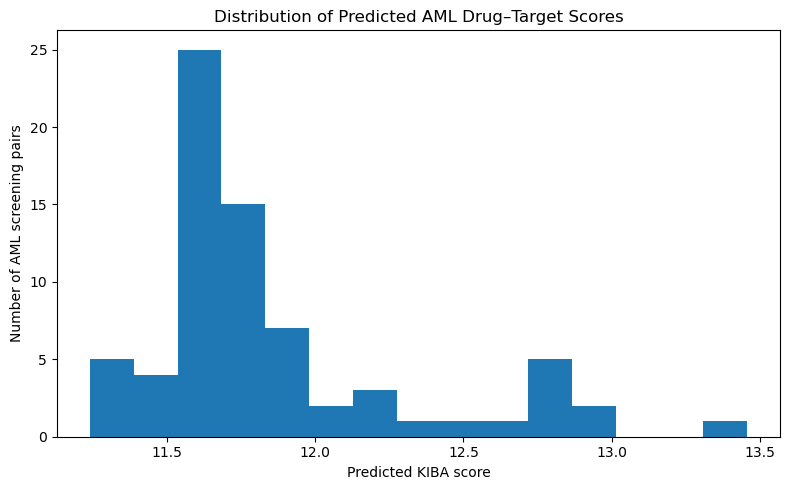

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/aml_predicted_kiba_score_distribution.png


In [92]:
plt.figure(figsize=(8, 5))

plt.hist(
    aml_screening_predictions_output_df[
        "predicted_kiba_score"
    ],
    bins=15,
)

plt.xlabel("Predicted KIBA score")
plt.ylabel("Number of AML screening pairs")

plt.title(
    "Distribution of Predicted AML "
    "Drug–Target Scores"
)

plt.tight_layout()

plt.savefig(
    aml_prediction_distribution_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(
    aml_prediction_distribution_plot_path
)

# Save prediction metadata

In [93]:
aml_prediction_summary = {
    "selected_model": "GAT + CNN",
    "checkpoint": str(
        aml_screening_checkpoint
    ),
    "training_dataset": "KIBA",
    "training_split": "random",
    "protein_representation": "CNN",
    "number_of_screening_pairs": int(
        len(
            aml_screening_predictions_output_df
        )
    ),
    "number_of_candidate_drugs": int(
        aml_screening_predictions_output_df[
            "drug_id"
        ].nunique()
    ),
    "number_of_aml_targets": int(
        aml_screening_predictions_output_df[
            "target_id"
        ].nunique()
    ),
    "checkpoint_training_overlap_pairs": int(
        aml_screening_predictions_output_df[
            "exact_pair_seen_in_checkpoint_train"
        ].sum()
    ),
    "minimum_predicted_kiba_score": float(
        aml_screening_predictions_output_df[
            "predicted_kiba_score"
        ].min()
    ),
    "maximum_predicted_kiba_score": float(
        aml_screening_predictions_output_df[
            "predicted_kiba_score"
        ].max()
    ),
    "mean_predicted_kiba_score": float(
        aml_screening_predictions_output_df[
            "predicted_kiba_score"
        ].mean()
    ),
    "prediction_runtime_seconds": float(
        aml_prediction_runtime_seconds
    ),
    "predictions_are_experimental": True,
    "ground_truth_available": False,
    "prediction_output": str(
        aml_screening_predictions_path
    ),
}

with open(
    aml_prediction_summary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        aml_prediction_summary,
        file,
        indent=4,
    )

print(
    json.dumps(
        aml_prediction_summary,
        indent=4,
    )
)

{
    "selected_model": "GAT + CNN",
    "checkpoint": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_kiba_gat_cnn_random.pt",
    "training_dataset": "KIBA",
    "training_split": "random",
    "protein_representation": "CNN",
    "number_of_screening_pairs": 72,
    "number_of_candidate_drugs": 12,
    "number_of_aml_targets": 6,
    "checkpoint_training_overlap_pairs": 0,
    "minimum_predicted_kiba_score": 11.238640785217285,
    "maximum_predicted_kiba_score": 13.457741737365723,
    "mean_predicted_kiba_score": 11.863018790880838,
    "prediction_runtime_seconds": 0.4998345000203699,
    "predictions_are_experimental": true,
    "ground_truth_available": false,
    "prediction_output": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/aml_gat_cnn_screening_predictions.csv"
}


# Confirm all prediction outputs

In [94]:
aml_prediction_outputs = [
    aml_screening_predictions_path,
    aml_screening_predictions_copy_path,
    aml_prediction_summary_path,
    aml_prediction_distribution_plot_path,
]

for output_path in aml_prediction_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in aml_prediction_outputs
)

assert len(
    aml_screening_predictions_output_df
) == len(
    aml_screening_pairs_df
)

assert not (
    aml_screening_predictions_output_df[
        "predicted_kiba_score"
    ].isna().any()
)

print()

print(
    "AML screening affinity prediction "
    "completed successfully."
)

aml_gat_cnn_screening_predictions.csv → True
aml_screening_predictions.csv → True
aml_prediction_summary.json → True
aml_predicted_kiba_score_distribution.png → True

AML screening affinity prediction completed successfully.


# Remove the screening model from memory

In [95]:
objects_to_remove = [
    "aml_screening_model",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if device.type == "mps":
    torch.mps.empty_cache()

elif device.type == "cuda":
    torch.cuda.empty_cache()

print(
    "AML GAT + CNN screening model "
    "removed from memory."
)

AML GAT + CNN screening model removed from memory.


## Phase 7 — Step 18C Complete

The selected KIBA GAT + CNN model generated predicted affinity scores for every candidate drug–AML target pair.

Each result contains:

- the predicted KIBA-scale score;
- drug and AML target identifiers;
- whether the pair was present in the checkpoint training data;
- the corresponding generalisation category;
- the benchmark setting most similar to the prediction.

These predictions are computational screening outputs and do not represent experimentally confirmed drug–target interactions.

The next step ranks candidate interactions, separates reference controls from repurposing candidates and identifies the strongest candidates for each AML target.

# Phase 7 — Step 18D: Rank AML Screening Predictions

This section ranks the predicted AML drug–target interactions.

The transformed KIBA benchmark used by the model is interpreted so that higher predicted scores indicate stronger predicted binding.

The analysis:

- ranks all drugs separately for each AML target;
- separates reference drugs from repurposing candidates;
- excludes checkpoint-training overlaps from the novel shortlist;
- identifies the strongest candidate pairs for each target;
- summarises candidate performance across all AML targets;
- saves the final computational shortlist.

These rankings are hypothesis-generation results and are not experimental evidence of therapeutic efficacy.

# Reload the raw AML predictions

In [96]:
assert aml_screening_predictions_path.exists(), (
    f"Missing prediction file: "
    f"{aml_screening_predictions_path}"
)

aml_ranked_predictions_df = pd.read_csv(
    aml_screening_predictions_path
)

print(
    "Prediction rows:",
    len(aml_ranked_predictions_df),
)

print(
    "Candidate drugs:",
    aml_ranked_predictions_df[
        "drug_id"
    ].nunique(),
)

print(
    "AML targets:",
    aml_ranked_predictions_df[
        "target_id"
    ].nunique(),
)

display(
    aml_ranked_predictions_df[
        [
            "pair_id",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "ranking_group",
        ]
    ].head()
)

Prediction rows: 72
Candidate drugs: 12
AML targets: 6


,pair_id,drug_name,gene_symbol,predicted_kiba_score,ranking_group
0,AMLPAIR_000001,enasidenib,BCL2,11.634454,reference_control
1,AMLPAIR_000002,enasidenib,FLT3,12.181962,reference_control
2,AMLPAIR_000003,enasidenib,IDH1,11.594416,reference_control
3,AMLPAIR_000004,enasidenib,IDH2,11.627043,reference_control
4,AMLPAIR_000005,enasidenib,MEN1,11.734586,reference_control


# Validate the ranking inputs

In [97]:
required_ranking_columns = [
    "pair_id",
    "drug_id",
    "drug_name",
    "target_id",
    "gene_symbol",
    "target_name",
    "predicted_kiba_score",
    "ranking_group",
    "checkpoint_prediction_status",
    "exact_pair_seen_in_checkpoint_train",
]

missing_ranking_columns = [
    column_name
    for column_name in required_ranking_columns
    if column_name
    not in aml_ranked_predictions_df.columns
]

if missing_ranking_columns:
    raise KeyError(
        "Prediction table is missing: "
        f"{missing_ranking_columns}"
    )

aml_ranked_predictions_df[
    "predicted_kiba_score"
] = pd.to_numeric(
    aml_ranked_predictions_df[
        "predicted_kiba_score"
    ],
    errors="coerce",
)

assert np.isfinite(
    aml_ranked_predictions_df[
        "predicted_kiba_score"
    ]
).all()

assert (
    aml_ranked_predictions_df[
        "pair_id"
    ].is_unique
)

print("AML ranking inputs validated.")

AML ranking inputs validated.


# Standardise Boolean columns

In [98]:
def ranking_boolean(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)

    return (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(
            {
                "true",
                "1",
                "yes",
                "y",
                "t",
            }
        )
    )


aml_ranked_predictions_df[
    "exact_pair_seen_in_checkpoint_train"
] = ranking_boolean(
    aml_ranked_predictions_df[
        "exact_pair_seen_in_checkpoint_train"
    ]
)

for optional_boolean_column in [
    "drug_seen_in_kiba",
    "target_seen_in_kiba",
    "is_reference_control",
    "novel_pair",
]:
    if (
        optional_boolean_column
        in aml_ranked_predictions_df.columns
    ):
        aml_ranked_predictions_df[
            optional_boolean_column
        ] = ranking_boolean(
            aml_ranked_predictions_df[
                optional_boolean_column
            ]
        )

print(
    "Checkpoint overlaps:",
    int(
        aml_ranked_predictions_df[
            "exact_pair_seen_in_checkpoint_train"
        ].sum()
    ),
)

Checkpoint overlaps: 0


# Confirm the processed KIBA score range

In [99]:
kiba_pairs_for_direction_path = (
    PROCESSED_DATA_DIR
    / "kiba_pairs.csv"
)

kiba_pairs_for_direction_df = pd.read_csv(
    kiba_pairs_for_direction_path
)

kiba_affinity_summary = (
    kiba_pairs_for_direction_df[
        "affinity"
    ]
    .describe()
)

display(kiba_affinity_summary)

print(
    "Minimum KIBA training label:",
    round(
        float(
            kiba_pairs_for_direction_df[
                "affinity"
            ].min()
        ),
        4,
    ),
)

print(
    "Maximum KIBA training label:",
    round(
        float(
            kiba_pairs_for_direction_df[
                "affinity"
            ].max()
        ),
        4,
    ),
)

KIBA_HIGHER_IS_STRONGER = True

assert KIBA_HIGHER_IS_STRONGER

print(
    "Ranking direction confirmed: "
    "higher transformed KIBA score "
    "= stronger predicted binding."
)

count    118254.000000
mean         11.719935
std           0.836947
min           0.000000
25%          11.200000
50%          11.500000
75%          11.923909
max          17.200179
Name: affinity, dtype: float64

Minimum KIBA training label: 0.0
Maximum KIBA training label: 17.2002
Ranking direction confirmed: higher transformed KIBA score = stronger predicted binding.


# Rank all screening pairs — Rank drugs within each AML target

In [100]:
aml_ranked_predictions_df[
    "all_drug_rank_within_target"
] = (
    aml_ranked_predictions_df
    .groupby("target_id")[
        "predicted_kiba_score"
    ]
    .rank(
        method="first",
        ascending=False,
    )
    .astype(int)
)

aml_ranked_predictions_df[
    "binding_percentile_within_target"
] = (
    aml_ranked_predictions_df
    .groupby("target_id")[
        "predicted_kiba_score"
    ]
    .rank(
        method="average",
        ascending=True,
        pct=True,
    )
)

aml_ranked_predictions_df[
    "target_rank_within_drug"
] = (
    aml_ranked_predictions_df
    .groupby("drug_id")[
        "predicted_kiba_score"
    ]
    .rank(
        method="first",
        ascending=False,
    )
    .astype(int)
)

aml_ranked_predictions_df = (
    aml_ranked_predictions_df
    .sort_values(
        [
            "target_id",
            "all_drug_rank_within_target",
        ]
    )
    .reset_index(drop=True)
)

display(
    aml_ranked_predictions_df[
        [
            "gene_symbol",
            "all_drug_rank_within_target",
            "drug_name",
            "predicted_kiba_score",
            "binding_percentile_within_target",
            "ranking_group",
        ]
    ].head(18).round(4)
)

,gene_symbol,all_drug_rank_within_target,drug_name,predicted_kiba_score,binding_percentile_within_target,ranking_group
0,MEN1,1,midostaurin,12.9496,1.0000,reference_control
1,MEN1,2,nilotinib,11.9350,0.9167,repurposing_candidate
2,MEN1,3,gilteritinib,11.9344,0.8333,reference_control
3,MEN1,4,sorafenib,11.8357,0.7500,repurposing_candidate
4,MEN1,5,quizartinib,11.8204,0.6667,reference_control
5,MEN1,6,sunitinib,11.8061,0.5833,repurposing_candidate
6,MEN1,7,enasidenib,11.7346,0.5000,reference_control
7,MEN1,8,ruxolitinib,11.7087,0.4167,repurposing_candidate
8,MEN1,9,venetoclax,11.7000,0.3333,reference_control
9,MEN1,10,ivosidenib,11.6754,0.2500,reference_control


# Reconstruct ranking groups safely

In [101]:
if (
    "is_reference_control"
    in aml_ranked_predictions_df.columns
):
    aml_ranked_predictions_df[
        "ranking_group"
    ] = np.where(
        aml_ranked_predictions_df[
            "is_reference_control"
        ],
        "reference_control",
        "repurposing_candidate",
    )

else:
    aml_ranked_predictions_df[
        "ranking_group"
    ] = (
        aml_ranked_predictions_df[
            "ranking_group"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

print(
    aml_ranked_predictions_df[
        "ranking_group"
    ].value_counts()
)

ranking_group
reference_control        36
repurposing_candidate    36
Name: count, dtype: int64


# Add interpretation-priority categories

In [102]:
evidence_priority_mapping = {
    "unseen_pair_seen_entities": 1,
    "cold_drug_like": 2,
    "cold_target_like": 2,
    "cold_drug_target_like": 3,
    "checkpoint_training_overlap": 4,
}

evidence_description_mapping = {
    "unseen_pair_seen_entities": (
        "Both entities were represented in "
        "KIBA, but the exact pair was not in "
        "checkpoint training."
    ),
    "cold_drug_like": (
        "The drug was unseen in KIBA and the "
        "prediction is cold-drug-like."
    ),
    "cold_target_like": (
        "The target was unseen in KIBA and the "
        "prediction is cold-target-like."
    ),
    "cold_drug_target_like": (
        "Both entities were unseen and the "
        "prediction is exploratory."
    ),
    "checkpoint_training_overlap": (
        "The exact interaction was represented "
        "in checkpoint training."
    ),
}

aml_ranked_predictions_df[
    "evidence_priority"
] = (
    aml_ranked_predictions_df[
        "checkpoint_prediction_status"
    ]
    .map(evidence_priority_mapping)
    .fillna(99)
    .astype(int)
)

aml_ranked_predictions_df[
    "ranking_interpretation"
] = (
    aml_ranked_predictions_df[
        "checkpoint_prediction_status"
    ]
    .map(evidence_description_mapping)
    .fillna(
        "Prediction status requires review."
    )
)

display(
    aml_ranked_predictions_df[
        [
            "drug_name",
            "gene_symbol",
            "checkpoint_prediction_status",
            "evidence_priority",
        ]
    ].head(12)
)

,drug_name,gene_symbol,checkpoint_prediction_status,evidence_priority
0,midostaurin,MEN1,cold_drug_target_like,3
1,nilotinib,MEN1,cold_drug_target_like,3
2,gilteritinib,MEN1,cold_drug_target_like,3
3,sorafenib,MEN1,cold_drug_target_like,3
4,quizartinib,MEN1,cold_drug_target_like,3
5,sunitinib,MEN1,cold_drug_target_like,3
6,enasidenib,MEN1,cold_drug_target_like,3
7,ruxolitinib,MEN1,cold_drug_target_like,3
8,venetoclax,MEN1,cold_drug_target_like,3
9,ivosidenib,MEN1,cold_drug_target_like,3


# Prepare the repurposing candidate pool — Create the eligible candidate-pair table

In [103]:
aml_candidate_pairs_df = (
    aml_ranked_predictions_df[
        (
            aml_ranked_predictions_df[
                "ranking_group"
            ]
            == "repurposing_candidate"
        )
        & (
            ~aml_ranked_predictions_df[
                "exact_pair_seen_in_checkpoint_train"
            ]
        )
    ]
    .copy()
)

print(
    "Eligible repurposing candidate pairs:",
    len(aml_candidate_pairs_df),
)

print(
    "Eligible candidate drugs:",
    aml_candidate_pairs_df[
        "drug_id"
    ].nunique(),
)

print(
    "AML targets represented:",
    aml_candidate_pairs_df[
        "target_id"
    ].nunique(),
)

assert not aml_candidate_pairs_df.empty

Eligible repurposing candidate pairs: 36
Eligible candidate drugs: 6
AML targets represented: 6


# Rank repurposing candidates within each target

In [104]:
aml_candidate_pairs_df[
    "candidate_rank_within_target"
] = (
    aml_candidate_pairs_df
    .groupby("target_id")[
        "predicted_kiba_score"
    ]
    .rank(
        method="first",
        ascending=False,
    )
    .astype(int)
)

aml_candidate_pairs_df[
    "candidate_percentile_within_target"
] = (
    aml_candidate_pairs_df
    .groupby("target_id")[
        "predicted_kiba_score"
    ]
    .rank(
        method="average",
        ascending=True,
        pct=True,
    )
)

aml_candidate_pairs_df = (
    aml_candidate_pairs_df
    .sort_values(
        [
            "target_id",
            "candidate_rank_within_target",
        ]
    )
    .reset_index(drop=True)
)

display(
    aml_candidate_pairs_df[
        [
            "gene_symbol",
            "candidate_rank_within_target",
            "drug_name",
            "predicted_kiba_score",
            "checkpoint_prediction_status",
        ]
    ].round(4)
)

,gene_symbol,candidate_rank_within_target,drug_name,predicted_kiba_score,checkpoint_prediction_status
0,MEN1,1,nilotinib,11.9350,cold_drug_target_like
1,MEN1,2,sorafenib,11.8357,cold_drug_target_like
2,MEN1,3,sunitinib,11.8061,cold_drug_target_like
3,MEN1,4,ruxolitinib,11.7087,cold_drug_target_like
4,MEN1,5,ponatinib,11.6119,cold_drug_target_like
5,MEN1,6,dasatinib,11.3800,cold_drug_target_like
6,IDH1,1,nilotinib,11.7881,cold_drug_target_like
7,IDH1,2,sorafenib,11.6546,cold_drug_target_like
8,IDH1,3,sunitinib,11.6157,cold_drug_target_like
9,IDH1,4,ruxolitinib,11.5685,cold_drug_target_like


# Select the top three candidates per AML target

In [105]:
TOP_CANDIDATES_PER_TARGET = 3

aml_top_candidates_per_target_df = (
    aml_candidate_pairs_df[
        aml_candidate_pairs_df[
            "candidate_rank_within_target"
        ]
        <= TOP_CANDIDATES_PER_TARGET
    ]
    .copy()
)

aml_top_candidates_per_target_df = (
    aml_top_candidates_per_target_df
    .sort_values(
        [
            "gene_symbol",
            "candidate_rank_within_target",
        ]
    )
    .reset_index(drop=True)
)

print(
    "Top candidate pairs selected:",
    len(
        aml_top_candidates_per_target_df
    ),
)

display(
    aml_top_candidates_per_target_df[
        [
            "gene_symbol",
            "candidate_rank_within_target",
            "drug_name",
            "predicted_kiba_score",
            "checkpoint_prediction_status",
            "evidence_priority",
        ]
    ].round(4)
)

Top candidate pairs selected: 18


,gene_symbol,candidate_rank_within_target,drug_name,predicted_kiba_score,checkpoint_prediction_status,evidence_priority
0,BCL2,1,nilotinib,11.8319,cold_drug_target_like,3
1,BCL2,2,sorafenib,11.7117,cold_drug_target_like,3
2,BCL2,3,sunitinib,11.6729,cold_drug_target_like,3
3,FLT3,1,sunitinib,12.9304,cold_drug_like,2
4,FLT3,2,sorafenib,12.6988,cold_drug_like,2
5,FLT3,3,nilotinib,12.5119,cold_drug_like,2
6,IDH1,1,nilotinib,11.7881,cold_drug_target_like,3
7,IDH1,2,sorafenib,11.6546,cold_drug_target_like,3
8,IDH1,3,sunitinib,11.6157,cold_drug_target_like,3
9,IDH2,1,nilotinib,11.8170,cold_drug_target_like,3


# Create an overall descriptive pair shortlist

In [106]:
OVERALL_SHORTLIST_SIZE = 10

aml_overall_candidate_shortlist_df = (
    aml_candidate_pairs_df
    .sort_values(
        [
            "candidate_percentile_within_target",
            "evidence_priority",
            "predicted_kiba_score",
        ],
        ascending=[
            False,
            True,
            False,
        ],
    )
    .head(
        OVERALL_SHORTLIST_SIZE
    )
    .reset_index(drop=True)
    .copy()
)

aml_overall_candidate_shortlist_df[
    "overall_shortlist_rank"
] = range(
    1,
    len(
        aml_overall_candidate_shortlist_df
    ) + 1,
)

shortlist_first_columns = [
    "overall_shortlist_rank",
    "pair_id",
    "drug_name",
    "gene_symbol",
    "predicted_kiba_score",
    "candidate_rank_within_target",
    "candidate_percentile_within_target",
    "checkpoint_prediction_status",
]

remaining_shortlist_columns = [
    column_name
    for column_name
    in aml_overall_candidate_shortlist_df.columns
    if column_name
    not in shortlist_first_columns
]

aml_overall_candidate_shortlist_df = (
    aml_overall_candidate_shortlist_df[
        shortlist_first_columns
        + remaining_shortlist_columns
    ]
)

display(
    aml_overall_candidate_shortlist_df[
        shortlist_first_columns
    ].round(4)
)

,overall_shortlist_rank,pair_id,drug_name,gene_symbol,predicted_kiba_score,candidate_rank_within_target,candidate_percentile_within_target,checkpoint_prediction_status
0,1,AMLPAIR_000068,sunitinib,FLT3,12.9304,1,1.0000,cold_drug_like
1,2,AMLPAIR_000047,nilotinib,MEN1,11.9350,1,1.0000,cold_drug_target_like
2,3,AMLPAIR_000048,nilotinib,IL3RA,11.8789,1,1.0000,cold_drug_target_like
3,4,AMLPAIR_000043,nilotinib,BCL2,11.8319,1,1.0000,cold_drug_target_like
4,5,AMLPAIR_000046,nilotinib,IDH2,11.8170,1,1.0000,cold_drug_target_like
5,6,AMLPAIR_000045,nilotinib,IDH1,11.7881,1,1.0000,cold_drug_target_like
6,7,AMLPAIR_000062,sorafenib,FLT3,12.6988,2,0.8333,cold_drug_like
7,8,AMLPAIR_000065,sorafenib,MEN1,11.8357,2,0.8333,cold_drug_target_like
8,9,AMLPAIR_000066,sorafenib,IL3RA,11.7169,2,0.8333,cold_drug_target_like
9,10,AMLPAIR_000061,sorafenib,BCL2,11.7117,2,0.8333,cold_drug_target_like


# Summarise candidate drugs across AML targets — Find each candidate drug’s highest-scoring target

In [107]:
candidate_best_target_df = (
    aml_candidate_pairs_df
    .sort_values(
        [
            "drug_id",
            "predicted_kiba_score",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .groupby(
        "drug_id",
        as_index=False,
    )
    .first()
    [
        [
            "drug_id",
            "gene_symbol",
            "target_name",
            "predicted_kiba_score",
            "candidate_rank_within_target",
            "checkpoint_prediction_status",
        ]
    ]
    .rename(
        columns={
            "gene_symbol": (
                "highest_scoring_target"
            ),
            "target_name": (
                "highest_scoring_target_name"
            ),
            "predicted_kiba_score": (
                "highest_predicted_kiba_score"
            ),
            "candidate_rank_within_target": (
                "rank_for_highest_scoring_target"
            ),
            "checkpoint_prediction_status": (
                "best_pair_prediction_status"
            ),
        }
    )
)

display(
    candidate_best_target_df.round(4)
)

,drug_id,highest_scoring_target,highest_scoring_target_name,highest_predicted_kiba_score,rank_for_highest_scoring_target,best_pair_prediction_status
0,PUBCHEM_216239,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.6988,2,cold_drug_like
1,PUBCHEM_24826799,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.1929,4,cold_drug_like
2,PUBCHEM_25126798,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.0423,5,cold_drug_like
3,PUBCHEM_3062316,FLT3,Receptor-type tyrosine-protein kinase FLT3,11.9202,6,cold_drug_like
4,PUBCHEM_5329102,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.9304,1,cold_drug_like
5,PUBCHEM_644241,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.5119,3,cold_drug_like


# Create the candidate-drug summary

In [108]:
aml_candidate_drug_summary_df = (
    aml_candidate_pairs_df
    .groupby(
        [
            "drug_id",
            "drug_name",
            "development_status",
        ],
        dropna=False,
    )
    .agg(
        aml_targets_screened=(
            "target_id",
            "nunique",
        ),
        mean_predicted_kiba_score=(
            "predicted_kiba_score",
            "mean",
        ),
        median_predicted_kiba_score=(
            "predicted_kiba_score",
            "median",
        ),
        mean_target_percentile=(
            "candidate_percentile_within_target",
            "mean",
        ),
        top_three_target_appearances=(
            "candidate_rank_within_target",
            lambda ranks: int(
                (ranks <= 3).sum()
            ),
        ),
        number_one_target_appearances=(
            "candidate_rank_within_target",
            lambda ranks: int(
                (ranks == 1).sum()
            ),
        ),
        exploratory_pair_count=(
            "checkpoint_prediction_status",
            lambda statuses: int(
                (
                    statuses
                    == "cold_drug_target_like"
                ).sum()
            ),
        ),
    )
    .reset_index()
)

aml_candidate_drug_summary_df = (
    aml_candidate_drug_summary_df
    .merge(
        candidate_best_target_df,
        on="drug_id",
        how="left",
        validate="one_to_one",
    )
)

aml_candidate_drug_summary_df = (
    aml_candidate_drug_summary_df
    .sort_values(
        [
            "mean_target_percentile",
            "number_one_target_appearances",
            "top_three_target_appearances",
            "highest_predicted_kiba_score",
        ],
        ascending=[
            False,
            False,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

aml_candidate_drug_summary_df.insert(
    0,
    "candidate_drug_rank",
    range(
        1,
        len(
            aml_candidate_drug_summary_df
        ) + 1,
    ),
)

display(
    aml_candidate_drug_summary_df.round(4)
)

,candidate_drug_rank,drug_id,drug_name,development_status,aml_targets_screened,mean_predicted_kiba_score,median_predicted_kiba_score,mean_target_percentile,top_three_target_appearances,number_one_target_appearances,exploratory_pair_count,highest_scoring_target,highest_scoring_target_name,highest_predicted_kiba_score,rank_for_highest_scoring_target,best_pair_prediction_status
0,1,PUBCHEM_644241,nilotinib,repurposing_candidate,6,11.9605,11.8554,0.9444,6,5,5,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.5119,3,cold_drug_like
1,2,PUBCHEM_216239,sorafenib,repurposing_candidate,6,11.8827,11.7143,0.8333,6,0,5,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.6988,2,cold_drug_like
2,3,PUBCHEM_5329102,sunitinib,repurposing_candidate,6,11.8896,11.6730,0.7222,6,1,5,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.9304,1,cold_drug_like
3,4,PUBCHEM_25126798,ruxolitinib,repurposing_candidate,6,11.6990,11.6367,0.4722,0,0,5,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.0423,5,cold_drug_like
4,5,PUBCHEM_24826799,ponatinib,repurposing_candidate,6,11.6306,11.5194,0.3611,0,0,5,FLT3,Receptor-type tyrosine-protein kinase FLT3,12.1929,4,cold_drug_like
5,6,PUBCHEM_3062316,dasatinib,repurposing_candidate,6,11.4042,11.3074,0.1667,0,0,5,FLT3,Receptor-type tyrosine-protein kinase FLT3,11.9202,6,cold_drug_like


# Create the target-level ranking summary

In [109]:
aml_target_ranking_summary_df = (
    aml_top_candidates_per_target_df[
        aml_top_candidates_per_target_df[
            "candidate_rank_within_target"
        ] == 1
    ]
    [
        [
            "target_id",
            "gene_symbol",
            "target_name",
            "drug_id",
            "drug_name",
            "predicted_kiba_score",
            "checkpoint_prediction_status",
            "evidence_priority",
        ]
    ]
    .rename(
        columns={
            "drug_id": (
                "top_candidate_drug_id"
            ),
            "drug_name": (
                "top_candidate_drug"
            ),
            "predicted_kiba_score": (
                "top_predicted_kiba_score"
            ),
        }
    )
    .sort_values(
        "gene_symbol"
    )
    .reset_index(drop=True)
)

display(
    aml_target_ranking_summary_df.round(4)
)

,target_id,gene_symbol,target_name,top_candidate_drug_id,top_candidate_drug,top_predicted_kiba_score,checkpoint_prediction_status,evidence_priority
0,P10415,BCL2,Apoptosis regulator Bcl-2,PUBCHEM_644241,nilotinib,11.8319,cold_drug_target_like,3
1,P36888,FLT3,Receptor-type tyrosine-protein kinase FLT3,PUBCHEM_5329102,sunitinib,12.9304,cold_drug_like,2
2,O75874,IDH1,Isocitrate dehydrogenase [NADP] cytoplasmic,PUBCHEM_644241,nilotinib,11.7881,cold_drug_target_like,3
3,P48735,IDH2,Isocitrate dehydrogenase [NADP] mitochondrial,PUBCHEM_644241,nilotinib,11.8170,cold_drug_target_like,3
4,P26951,IL3RA,Interleukin-3 receptor subunit alpha (CD123),PUBCHEM_644241,nilotinib,11.8789,cold_drug_target_like,3
5,O00255,MEN1,Menin,PUBCHEM_644241,nilotinib,11.9350,cold_drug_target_like,3


# Keep reference drugs for comparison — Create the reference-drug ranking table

In [110]:
aml_reference_drug_pairs_df = (
    aml_ranked_predictions_df[
        aml_ranked_predictions_df[
            "ranking_group"
        ]
        == "reference_control"
    ]
    .copy()
)

aml_reference_drug_pairs_df[
    "reference_drug_rank_within_target"
] = (
    aml_reference_drug_pairs_df
    .groupby("target_id")[
        "predicted_kiba_score"
    ]
    .rank(
        method="first",
        ascending=False,
    )
    .astype(int)
)

aml_reference_drug_pairs_df = (
    aml_reference_drug_pairs_df
    .sort_values(
        [
            "gene_symbol",
            "reference_drug_rank_within_target",
        ]
    )
    .reset_index(drop=True)
)

display(
    aml_reference_drug_pairs_df[
        [
            "gene_symbol",
            "reference_drug_rank_within_target",
            "drug_name",
            "predicted_kiba_score",
            "exact_pair_seen_in_checkpoint_train",
        ]
    ].round(4)
)

,gene_symbol,reference_drug_rank_within_target,drug_name,predicted_kiba_score,exact_pair_seen_in_checkpoint_train
0,BCL2,1,midostaurin,12.8362,False
1,BCL2,2,gilteritinib,11.8201,False
2,BCL2,3,quizartinib,11.6874,False
3,BCL2,4,enasidenib,11.6345,False
4,BCL2,5,venetoclax,11.5969,False
5,BCL2,6,ivosidenib,11.5581,False
6,FLT3,1,midostaurin,13.4577,False
7,FLT3,2,quizartinib,12.8089,False
8,FLT3,3,gilteritinib,12.3261,False
9,FLT3,4,venetoclax,12.2654,False


# Save final ranking outputs

In [111]:
aml_ranked_predictions_path = (
    PREDICTIONS_DIR
    / "aml_ranked_screening_predictions.csv"
)

aml_candidate_pairs_path = (
    AML_DATA_DIR
    / "aml_repurposing_candidate_pairs.csv"
)

aml_top_candidates_per_target_path = (
    AML_DATA_DIR
    / "aml_top_candidates_per_target.csv"
)

aml_overall_candidate_shortlist_path = (
    AML_DATA_DIR
    / "aml_overall_candidate_shortlist.csv"
)

aml_candidate_drug_summary_path = (
    AML_DATA_DIR
    / "aml_candidate_drug_summary.csv"
)

aml_target_ranking_summary_path = (
    AML_DATA_DIR
    / "aml_target_ranking_summary.csv"
)

aml_reference_drug_pairs_path = (
    AML_DATA_DIR
    / "aml_reference_drug_rankings.csv"
)

aml_ranking_summary_path = (
    AML_DATA_DIR
    / "aml_ranking_summary.json"
)

print("Ranked prediction output:")
print(aml_ranked_predictions_path)

Ranked prediction output:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/aml_ranked_screening_predictions.csv


# Save all ranking tables

In [112]:
aml_ranked_predictions_df.to_csv(
    aml_ranked_predictions_path,
    index=False,
)

aml_candidate_pairs_df.to_csv(
    aml_candidate_pairs_path,
    index=False,
)

aml_top_candidates_per_target_df.to_csv(
    aml_top_candidates_per_target_path,
    index=False,
)

aml_overall_candidate_shortlist_df.to_csv(
    aml_overall_candidate_shortlist_path,
    index=False,
)

aml_candidate_drug_summary_df.to_csv(
    aml_candidate_drug_summary_path,
    index=False,
)

aml_target_ranking_summary_df.to_csv(
    aml_target_ranking_summary_path,
    index=False,
)

aml_reference_drug_pairs_df.to_csv(
    aml_reference_drug_pairs_path,
    index=False,
)

print("AML ranking tables saved.")

AML ranking tables saved.


# Plot the drug–target prediction heatmap

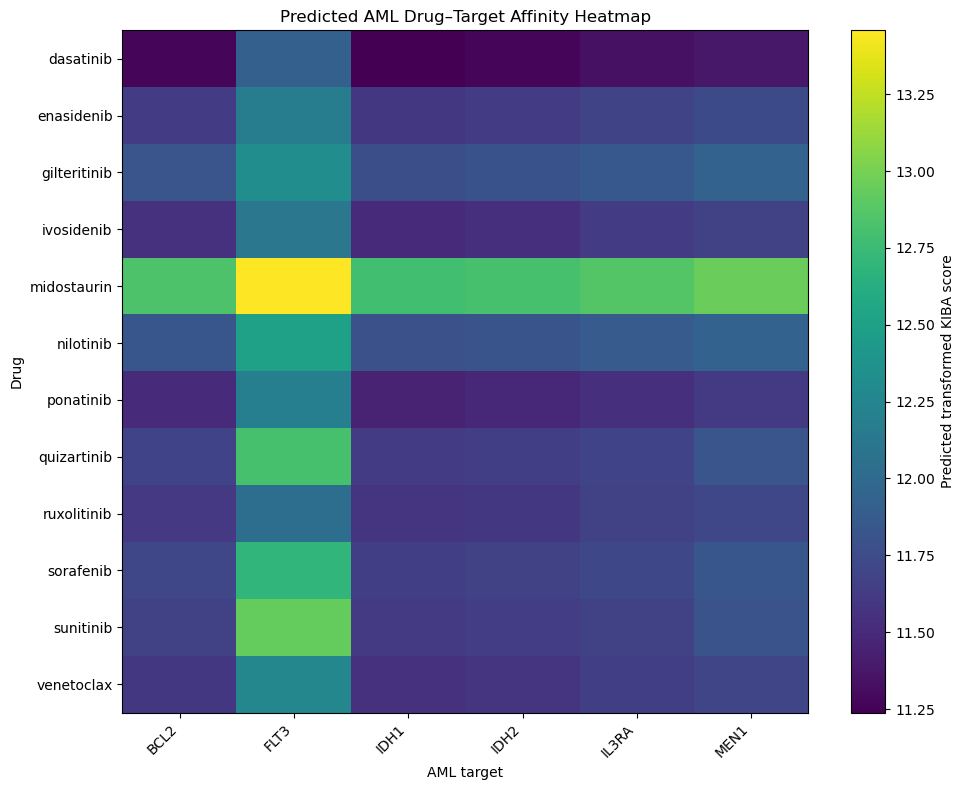

Heatmap saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/aml_drug_target_score_heatmap.png


In [113]:
aml_score_matrix = (
    aml_ranked_predictions_df
    .pivot(
        index="drug_name",
        columns="gene_symbol",
        values="predicted_kiba_score",
    )
)

aml_score_matrix = (
    aml_score_matrix
    .sort_index()
)

plt.figure(
    figsize=(10, 8)
)

plt.imshow(
    aml_score_matrix.to_numpy(),
    aspect="auto",
)

plt.colorbar(
    label="Predicted transformed KIBA score"
)

plt.xticks(
    range(
        len(
            aml_score_matrix.columns
        )
    ),
    aml_score_matrix.columns,
    rotation=45,
    ha="right",
)

plt.yticks(
    range(
        len(
            aml_score_matrix.index
        )
    ),
    aml_score_matrix.index,
)

plt.xlabel("AML target")
plt.ylabel("Drug")

plt.title(
    "Predicted AML Drug–Target "
    "Affinity Heatmap"
)

plt.tight_layout()

aml_score_heatmap_path = (
    PLOTS_DIR
    / "aml_drug_target_score_heatmap.png"
)

plt.savefig(
    aml_score_heatmap_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Heatmap saved to:")
print(aml_score_heatmap_path)

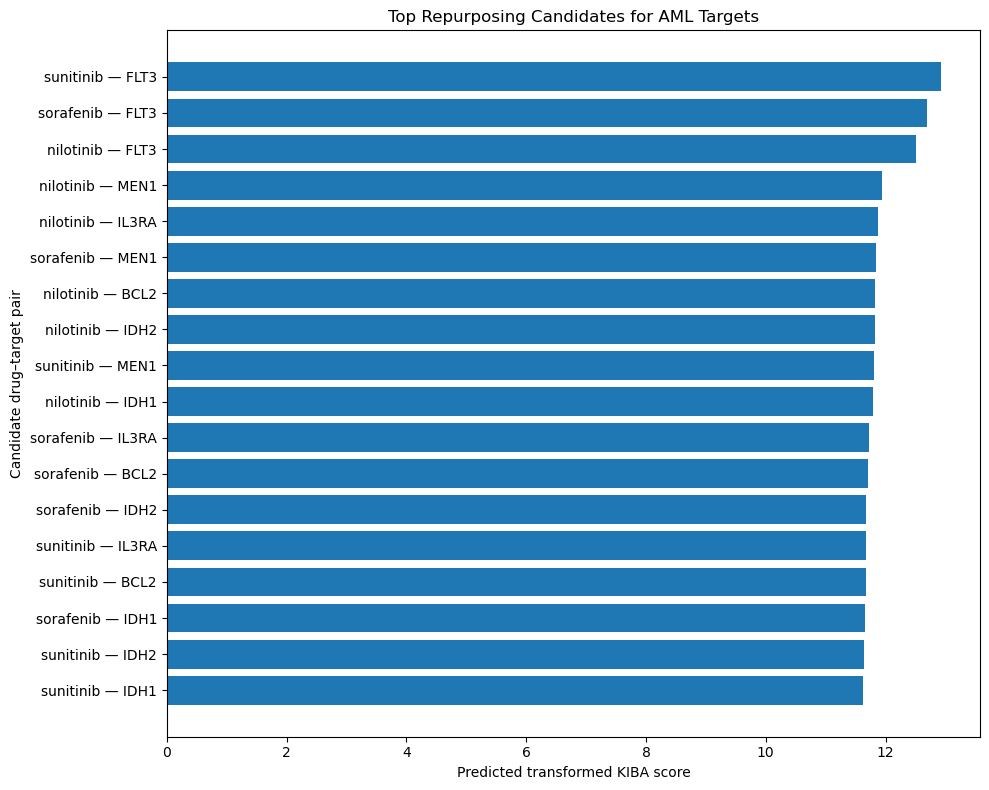

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/aml_top_candidate_pairs.png


In [114]:
top_candidate_plot_df = (
    aml_top_candidates_per_target_df
    .copy()
)

top_candidate_plot_df[
    "pair_label"
] = (
    top_candidate_plot_df[
        "drug_name"
    ]
    + " — "
    + top_candidate_plot_df[
        "gene_symbol"
    ]
)

top_candidate_plot_df = (
    top_candidate_plot_df
    .sort_values(
        "predicted_kiba_score",
        ascending=True,
    )
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_candidate_plot_df[
        "pair_label"
    ],
    top_candidate_plot_df[
        "predicted_kiba_score"
    ],
)

plt.xlabel(
    "Predicted transformed KIBA score"
)

plt.ylabel(
    "Candidate drug–target pair"
)

plt.title(
    "Top Repurposing Candidates "
    "for AML Targets"
)

plt.tight_layout()

aml_top_candidate_pairs_plot_path = (
    PLOTS_DIR
    / "aml_top_candidate_pairs.png"
)

plt.savefig(
    aml_top_candidate_pairs_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(
    aml_top_candidate_pairs_plot_path
)

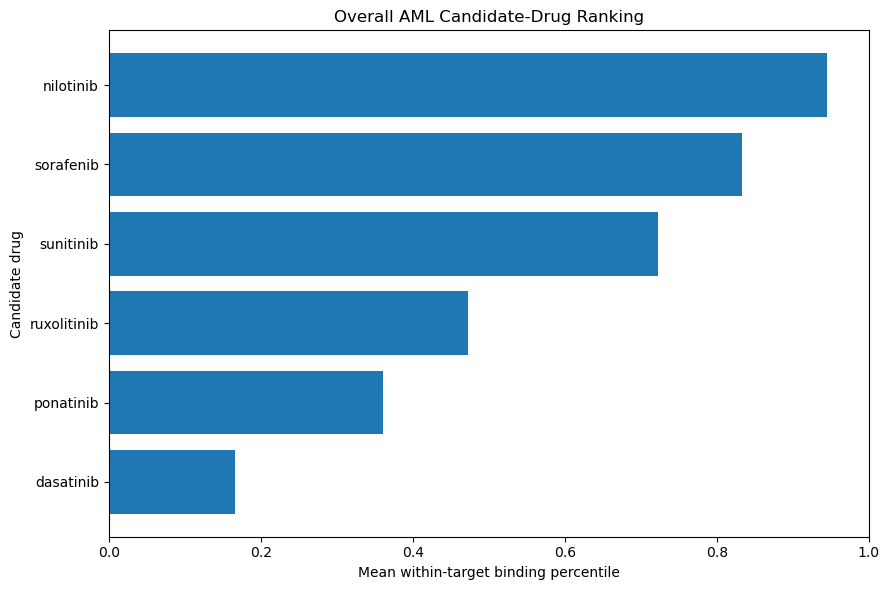

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/aml_candidate_drug_summary_ranking.png


In [115]:
candidate_summary_plot_df = (
    aml_candidate_drug_summary_df
    .sort_values(
        "mean_target_percentile",
        ascending=True,
    )
)

plt.figure(figsize=(9, 6))

plt.barh(
    candidate_summary_plot_df[
        "drug_name"
    ],
    candidate_summary_plot_df[
        "mean_target_percentile"
    ],
)

plt.xlabel(
    "Mean within-target binding percentile"
)

plt.ylabel("Candidate drug")

plt.title(
    "Overall AML Candidate-Drug Ranking"
)

plt.xlim(0, 1)

plt.tight_layout()

aml_candidate_drug_summary_plot_path = (
    PLOTS_DIR
    / "aml_candidate_drug_summary_ranking.png"
)

plt.savefig(
    aml_candidate_drug_summary_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(
    aml_candidate_drug_summary_plot_path
)

In [116]:
top_ranked_candidate = (
    aml_candidate_drug_summary_df.iloc[0]
)

aml_ranking_summary = {
    "selected_model": "GAT + CNN",
    "training_dataset": "KIBA",
    "ranking_direction": (
        "higher transformed KIBA score "
        "indicates stronger predicted binding"
    ),
    "number_of_ranked_pairs": int(
        len(
            aml_ranked_predictions_df
        )
    ),
    "eligible_repurposing_pairs": int(
        len(
            aml_candidate_pairs_df
        )
    ),
    "top_candidates_per_target": int(
        TOP_CANDIDATES_PER_TARGET
    ),
    "number_of_target_shortlist_pairs": int(
        len(
            aml_top_candidates_per_target_df
        )
    ),
    "overall_shortlist_size": int(
        len(
            aml_overall_candidate_shortlist_df
        )
    ),
    "highest_ranked_candidate_drug": str(
        top_ranked_candidate[
            "drug_name"
        ]
    ),
    "highest_ranked_candidate_drug_id": str(
        top_ranked_candidate[
            "drug_id"
        ]
    ),
    "highest_ranked_candidate_target": str(
        top_ranked_candidate[
            "highest_scoring_target"
        ]
    ),
    "candidate_selection_basis": (
        "Within-target predicted affinity "
        "ranking with checkpoint-training "
        "overlaps and reference drugs excluded "
        "from the repurposing shortlist."
    ),
    "outputs": {
        "ranked_predictions": str(
            aml_ranked_predictions_path
        ),
        "candidate_pairs": str(
            aml_candidate_pairs_path
        ),
        "top_candidates_per_target": str(
            aml_top_candidates_per_target_path
        ),
        "overall_shortlist": str(
            aml_overall_candidate_shortlist_path
        ),
        "candidate_drug_summary": str(
            aml_candidate_drug_summary_path
        ),
    },
}

with open(
    aml_ranking_summary_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        aml_ranking_summary,
        file,
        indent=4,
    )

print(
    json.dumps(
        aml_ranking_summary,
        indent=4,
    )
)

{
    "selected_model": "GAT + CNN",
    "training_dataset": "KIBA",
    "ranking_direction": "higher transformed KIBA score indicates stronger predicted binding",
    "number_of_ranked_pairs": 72,
    "eligible_repurposing_pairs": 36,
    "top_candidates_per_target": 3,
    "number_of_target_shortlist_pairs": 18,
    "overall_shortlist_size": 10,
    "highest_ranked_candidate_drug": "nilotinib",
    "highest_ranked_candidate_drug_id": "PUBCHEM_644241",
    "highest_ranked_candidate_target": "FLT3",
    "candidate_selection_basis": "Within-target predicted affinity ranking with checkpoint-training overlaps and reference drugs excluded from the repurposing shortlist.",
    "outputs": {
        "ranked_predictions": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/aml_ranked_screening_predictions.csv",
        "candidate_pairs": "/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireN

In [117]:
print("Top candidate for each AML target")

display(
    aml_target_ranking_summary_df[
        [
            "gene_symbol",
            "top_candidate_drug",
            "top_predicted_kiba_score",
            "checkpoint_prediction_status",
        ]
    ].round(4)
)

print()

print("Overall candidate-drug ranking")

display(
    aml_candidate_drug_summary_df[
        [
            "candidate_drug_rank",
            "drug_name",
            "mean_target_percentile",
            "number_one_target_appearances",
            "top_three_target_appearances",
            "highest_scoring_target",
            "highest_predicted_kiba_score",
        ]
    ].round(4)
)

print()

print("Overall pair shortlist")

display(
    aml_overall_candidate_shortlist_df[
        [
            "overall_shortlist_rank",
            "drug_name",
            "gene_symbol",
            "predicted_kiba_score",
            "candidate_rank_within_target",
            "checkpoint_prediction_status",
        ]
    ].round(4)
)

Top candidate for each AML target


,gene_symbol,top_candidate_drug,top_predicted_kiba_score,checkpoint_prediction_status
0,BCL2,nilotinib,11.8319,cold_drug_target_like
1,FLT3,sunitinib,12.9304,cold_drug_like
2,IDH1,nilotinib,11.7881,cold_drug_target_like
3,IDH2,nilotinib,11.8170,cold_drug_target_like
4,IL3RA,nilotinib,11.8789,cold_drug_target_like
5,MEN1,nilotinib,11.9350,cold_drug_target_like



Overall candidate-drug ranking


,candidate_drug_rank,drug_name,mean_target_percentile,number_one_target_appearances,top_three_target_appearances,highest_scoring_target,highest_predicted_kiba_score
0,1,nilotinib,0.9444,5,6,FLT3,12.5119
1,2,sorafenib,0.8333,0,6,FLT3,12.6988
2,3,sunitinib,0.7222,1,6,FLT3,12.9304
3,4,ruxolitinib,0.4722,0,0,FLT3,12.0423
4,5,ponatinib,0.3611,0,0,FLT3,12.1929
5,6,dasatinib,0.1667,0,0,FLT3,11.9202



Overall pair shortlist


,overall_shortlist_rank,drug_name,gene_symbol,predicted_kiba_score,candidate_rank_within_target,checkpoint_prediction_status
0,1,sunitinib,FLT3,12.9304,1,cold_drug_like
1,2,nilotinib,MEN1,11.9350,1,cold_drug_target_like
2,3,nilotinib,IL3RA,11.8789,1,cold_drug_target_like
3,4,nilotinib,BCL2,11.8319,1,cold_drug_target_like
4,5,nilotinib,IDH2,11.8170,1,cold_drug_target_like
5,6,nilotinib,IDH1,11.7881,1,cold_drug_target_like
6,7,sorafenib,FLT3,12.6988,2,cold_drug_like
7,8,sorafenib,MEN1,11.8357,2,cold_drug_target_like
8,9,sorafenib,IL3RA,11.7169,2,cold_drug_target_like
9,10,sorafenib,BCL2,11.7117,2,cold_drug_target_like


# Confirm all Step 18D outputs

In [118]:
aml_ranking_outputs = [
    aml_ranked_predictions_path,
    aml_candidate_pairs_path,
    aml_top_candidates_per_target_path,
    aml_overall_candidate_shortlist_path,
    aml_candidate_drug_summary_path,
    aml_target_ranking_summary_path,
    aml_reference_drug_pairs_path,
    aml_ranking_summary_path,
    aml_score_heatmap_path,
    aml_top_candidate_pairs_plot_path,
    aml_candidate_drug_summary_plot_path,
]

for output_path in aml_ranking_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path
    in aml_ranking_outputs
)

assert not aml_candidate_pairs_df.empty

assert not (
    aml_candidate_pairs_df[
        "exact_pair_seen_in_checkpoint_train"
    ].any()
)

assert (
    aml_candidate_pairs_df[
        "ranking_group"
    ]
    == "repurposing_candidate"
).all()

print()

print(
    "AML candidate ranking and selection "
    "completed successfully."
)

aml_ranked_screening_predictions.csv → True
aml_repurposing_candidate_pairs.csv → True
aml_top_candidates_per_target.csv → True
aml_overall_candidate_shortlist.csv → True
aml_candidate_drug_summary.csv → True
aml_target_ranking_summary.csv → True
aml_reference_drug_rankings.csv → True
aml_ranking_summary.json → True
aml_drug_target_score_heatmap.png → True
aml_top_candidate_pairs.png → True
aml_candidate_drug_summary_ranking.png → True

AML candidate ranking and selection completed successfully.


# Phase 7 Complete

The selected GAT + CNN model was applied to all candidate drug–AML target combinations.

The predictions were ranked primarily within each AML target. Reference drugs and interactions overlapping with checkpoint training were retained for comparison but excluded from the novel repurposing shortlist.

The final outputs include:

- all ranked AML drug–target predictions;
- eligible repurposing candidate pairs;
- the top three candidates for each AML target;
- an overall descriptive pair shortlist;
- an overall candidate-drug summary;
- target-level candidate summaries;
- prediction heatmaps and ranking plots.

The predictions represent computational hypotheses and require external biological and pharmacological validation.